<a href="https://colab.research.google.com/github/elsiejy/Capstone/blob/main/Capstone_Hotel_Bookings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 1: Descriptive Analysis

### 1. Import libraries
Import the libaries into the notebook

In [ ]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# importing sklearn module for predictive analysis
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics
from sklearn.preprocessing import MinMaxScaler

# ignore the warnings that may appear
import warnings
warnings.filterwarnings("ignore")

### 2. Import data

Import csv files into the notebook. Here the file is hosted in github thus we will read the file directly from github

In [ ]:
# load dataset1: booking.csv
bookings = pd.read_csv('https://raw.githubusercontent.com/elsiejy/Capstone/refs/heads/main/Bookings.csv')
display(bookings.info())
display(bookings.head())
display(bookings.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 28 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   Booking_ID                      119390 non-null  int64  
 1   Hotel_ID                        119390 non-null  int64  
 2   Market_Segment_ID               119390 non-null  int64  
 3   Customer_Type_ID                119390 non-null  int64  
 4   Reservation_ID                  119390 non-null  int64  
 5   is_canceled                     119390 non-null  int64  
 6   lead_time                       119390 non-null  int64  
 7   arrival_date_year               119390 non-null  int64  
 8   arrival_date_month              119390 non-null  object 
 9   arrival_date_week_number        119390 non-null  int64  
 10  arrival_date_day_of_month       119390 non-null  int64  
 11  stays_in_weekend_nights         119390 non-null  int64  
 12  stays_in_week_ni

None

,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,...,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,reservation_status_date
0,1,1,1,1,1,0,342,2015,July,27,...,0,0,3,NaN,NaN,0,0.0,0,0,2015-07-01
1,2,1,1,1,1,0,737,2015,July,27,...,0,0,4,NaN,NaN,0,0.0,0,0,2015-07-01
2,3,1,1,1,1,0,7,2015,July,27,...,0,0,0,NaN,NaN,0,75.0,0,0,2015-07-02
3,4,1,2,1,1,0,13,2015,July,27,...,0,0,0,304.0,NaN,0,75.0,0,0,2015-07-02
4,5,1,3,1,1,0,14,2015,July,27,...,0,0,0,240.0,NaN,0,98.0,0,1,2015-07-03


,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,...,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,...,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,59695.500000,1.664461,4.262032,5.089044,1.380526,0.370416,104.011416,2016.156554,27.165173,15.798241,...,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,34465.068657,0.472181,3.071532,5.250009,0.505913,0.482918,106.863097,0.707476,13.605138,8.780829,...,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,2015.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,29848.250000,1.000000,3.000000,1.000000,1.000000,0.000000,18.000000,2016.000000,16.000000,8.000000,...,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,59695.500000,2.000000,3.000000,3.000000,1.000000,0.000000,69.000000,2016.000000,28.000000,16.000000,...,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,89542.750000,2.000000,4.000000,8.000000,2.000000,1.000000,160.000000,2017.000000,38.000000,23.000000,...,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,119390.000000,2.000000,26.000000,36.000000,3.000000,1.000000,737.000000,2017.000000,53.000000,31.000000,...,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [ ]:
# print the number of null values in each column in booking
bookings.isnull().sum()

,0
Booking_ID,0
Hotel_ID,0
Market_Segment_ID,0
Customer_Type_ID,0
Reservation_ID,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0


In [ ]:
# load dataset2: customertype.csv
cust_type = pd.read_csv('https://raw.githubusercontent.com/elsiejy/Capstone/refs/heads/main/CustomerTypes.csv')
display(cust_type.info())
display(cust_type.head())
display(cust_type.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Customer_Type_ID  36 non-null     int64 
 1   customer_type     36 non-null     object
 2   deposit_type      36 non-null     object
 3   meal              36 non-null     object
dtypes: int64(1), object(3)
memory usage: 1.3+ KB


None

,Customer_Type_ID,customer_type,deposit_type,meal
0,1,Transient,No Deposit,BB
1,2,Transient,No Deposit,FB
2,3,Transient,No Deposit,HB
3,4,Contract,No Deposit,BB
4,5,Contract,No Deposit,HB


,Customer_Type_ID
count,36.000000
mean,18.500000
std,10.535654
min,1.000000
25%,9.750000
50%,18.500000
75%,27.250000
max,36.000000


In [ ]:
# print the number of null values in each column in cust_type
cust_type.isnull().sum()

,0
Customer_Type_ID,0
customer_type,0
deposit_type,0
meal,0


In [ ]:
# load dataset3: hotel.csv
hotel_type = pd.read_csv('https://raw.githubusercontent.com/elsiejy/Capstone/refs/heads/main/Hotels.csv')
display(hotel_type.info())
display(hotel_type.head())
display(hotel_type.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Hotel_ID  2 non-null      int64 
 1   hotel     2 non-null      object
dtypes: int64(1), object(1)
memory usage: 164.0+ bytes


None

,Hotel_ID,hotel
0,1,Resort Hotel
1,2,City Hotel


,Hotel_ID
count,2.000000
mean,1.500000
std,0.707107
min,1.000000
25%,1.250000
50%,1.500000
75%,1.750000
max,2.000000


In [ ]:
# print the number of null values in each column in hotel_type
hotel_type.isnull().sum()

,0
Hotel_ID,0
hotel,0


In [ ]:
# load dataset4: marketsegment.csv
market_seg = pd.read_csv('https://raw.githubusercontent.com/elsiejy/Capstone/refs/heads/main/MarketSegments.csv')
display(market_seg.info())
display(market_seg.head())
display(market_seg.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26 entries, 0 to 25
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Market_Segment_ID     26 non-null     int64 
 1   market_segment        26 non-null     object
 2   distribution_channel  26 non-null     object
dtypes: int64(1), object(2)
memory usage: 756.0+ bytes


None

,Market_Segment_ID,market_segment,distribution_channel
0,1,Direct,Direct
1,2,Corporate,Corporate
2,3,Online TA,TA/TO
3,4,Offline TA/TO,TA/TO
4,5,Complementary,Direct


,Market_Segment_ID
count,26.000000
mean,13.500000
std,7.648529
min,1.000000
25%,7.250000
50%,13.500000
75%,19.750000
max,26.000000


In [ ]:
# print the number of null values in each column in market_seg
market_seg.isnull().sum()

,0
Market_Segment_ID,0
market_segment,0
distribution_channel,0


In [ ]:
# load dataset5: reservationstatus.csv
res_sts = pd.read_csv('https://raw.githubusercontent.com/elsiejy/Capstone/refs/heads/main/ReservationStatus.csv')
display(res_sts .info())
display(res_sts .head())
display(res_sts .describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 2 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Reservation_ID      3 non-null      int64 
 1   reservation_status  3 non-null      object
dtypes: int64(1), object(1)
memory usage: 180.0+ bytes


None

,Reservation_ID,reservation_status
0,1,Check-Out
1,2,Canceled
2,3,No-Show


,Reservation_ID
count,3.0
mean,2.0
std,1.0
min,1.0
25%,1.5
50%,2.0
75%,2.5
max,3.0


In [ ]:
# print the number of null values in each column in res_sts
res_sts.isnull().sum()

,0
Reservation_ID,0
reservation_status,0


Observation from booking dataset
- There are a total of 119,390 booking records
- Hotel_ID, Market_Segment_ID, Customer_Type_ID, Reservation_ID are foreign keys
- NULL values exist in children, country, agent, company
- reservation_status_date should be date time
- children, agent, and company should be int
- is_repeated_guest and is_canceled should be boolean

Observation from other dataset
- No empty values

### 3. Data Cleansing & Preparation

Let's clean the dataset. We'll identify missing values, handle empty rows, correct data types, and prepare the dataset for analysis.

Dataset 1: Booking
1. Derive check-in date
2. Update data type for reservation_status_date
3. Update data type for is_repeated_guest and is_canceled
4. Update data type for children, agent and company
5. Handle NULL values for children, country, agent, company

In [ ]:
# 1. Derive check-in date
# combine arrival_date_year, arrival_date_month and arrival_date_day_of_month into strings
booking_date_strings = (
    bookings['arrival_date_year'].astype(str) + '-' +
    bookings['arrival_date_month'].astype(str) + '-' +
    bookings['arrival_date_day_of_month'].astype(str)
)

# convert booking_date_strings to datetime then format as YYYY-MM-DD text
bookings['checkin_date'] = pd.to_datetime(booking_date_strings).dt.strftime('%Y-%m-%d')

# convert that string into a proper pandas datetime object
bookings['checkin_date'] = pd.to_datetime(booking_date_strings)

# verify that first 5 rows of checkin_date
print(bookings['checkin_date'].head())




0   2015-07-01
1   2015-07-01
2   2015-07-01
3   2015-07-01
4   2015-07-01
Name: checkin_date, dtype: datetime64[ns]


In [ ]:
# 2. Update data type for reservation_status_date
# convert reservation_status_date to datetime format
bookings['reservation_status_date'] = pd.to_datetime(bookings['reservation_status_date'])

# view the first 5 rows of reservation_status_date
print(bookings['reservation_status_date'].head())

0   2015-07-01
1   2015-07-01
2   2015-07-02
3   2015-07-02
4   2015-07-03
Name: reservation_status_date, dtype: datetime64[ns]


In [ ]:
# 3. Update data type for is_repeated_guest and is_canceled
# change datatype from int to boolean
bookings[['is_repeated_guest', 'is_canceled']] = bookings[['is_repeated_guest', 'is_canceled']].astype(bool)

# verify count of is_repeated_guest and is_canceled
print(bookings['is_canceled'].value_counts())
print(bookings['is_repeated_guest'].value_counts())

# confirm values are only false, true
print(bookings['is_canceled'].unique())
print(bookings['is_repeated_guest'].unique())


is_canceled
False    75166
True     44224
Name: count, dtype: int64
is_repeated_guest
False    115580
True       3810
Name: count, dtype: int64
[False  True]
[False  True]


In [ ]:
# 4. Update data type for children, agent and company
# change datatype from float to int
bookings[['children', 'agent', 'company']] = bookings[['children', 'agent', 'company']].astype('Int64')

In [ ]:
# 5. Handle NULL values for children, country, agent, company
# handle NULL value for children by replacing NULL with 0
bookings['children'] = bookings['children'].fillna(0)

# handle NULL value for country by replacing NULL with UNKNOWN
bookings['country'] = bookings['country'].fillna('Unknown')

# handle NULL value for agent by replacing NULL with 0
bookings['agent'] = bookings['agent'].fillna(0)

# handle NULL value for company by replacing NULL with 0
bookings['company'] = bookings['company'].fillna(0)

In [ ]:
# verify null values for each column in booking
bookings.isnull().sum()

,0
Booking_ID,0
Hotel_ID,0
Market_Segment_ID,0
Customer_Type_ID,0
Reservation_ID,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0


In [ ]:
# check booking data
display(bookings.info())
display(bookings.head())
display(bookings.describe(include='all'))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 29 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   Booking_ID                      119390 non-null  int64         
 1   Hotel_ID                        119390 non-null  int64         
 2   Market_Segment_ID               119390 non-null  int64         
 3   Customer_Type_ID                119390 non-null  int64         
 4   Reservation_ID                  119390 non-null  int64         
 5   is_canceled                     119390 non-null  bool          
 6   lead_time                       119390 non-null  int64         
 7   arrival_date_year               119390 non-null  int64         
 8   arrival_date_month              119390 non-null  object        
 9   arrival_date_week_number        119390 non-null  int64         
 10  arrival_date_day_of_month       119390 non-null  int64  

None

,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,...,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,reservation_status_date,checkin_date
0,1,1,1,1,1,False,342,2015,July,27,...,0,3,0,0,0,0.0,0,0,2015-07-01,2015-07-01
1,2,1,1,1,1,False,737,2015,July,27,...,0,4,0,0,0,0.0,0,0,2015-07-01,2015-07-01
2,3,1,1,1,1,False,7,2015,July,27,...,0,0,0,0,0,75.0,0,0,2015-07-02,2015-07-01
3,4,1,2,1,1,False,13,2015,July,27,...,0,0,304,0,0,75.0,0,0,2015-07-02,2015-07-01
4,5,1,3,1,1,False,14,2015,July,27,...,0,0,240,0,0,98.0,0,1,2015-07-03,2015-07-01


,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,...,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,reservation_status_date,checkin_date
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390,119390.000000,119390.000000,119390,119390.000000,...,119390.000000,119390.000000,119390.0,119390.0,119390.000000,119390.000000,119390.000000,119390.000000,119390,119390
unique,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,12,NaN,...,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN,August,NaN,...,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,75166,NaN,NaN,13877,NaN,...,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN
mean,59695.500000,1.664461,4.262032,5.089044,1.380526,NaN,104.011416,2016.156554,NaN,27.165173,...,0.137097,0.221124,74.828319,10.775157,2.321149,101.831122,0.062518,0.571363,2016-07-30 00:24:47.883407104,2016-08-28 16:39:45.727447808
min,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,0.000000,2015.000000,NaN,1.000000,...,0.000000,0.000000,0.0,0.0,0.000000,-6.380000,0.000000,0.000000,2014-10-17 00:00:00,2015-07-01 00:00:00
25%,29848.250000,1.000000,3.000000,1.000000,1.000000,NaN,18.000000,2016.000000,NaN,16.000000,...,0.000000,0.000000,7.0,0.0,0.000000,69.290000,0.000000,0.000000,2016-02-01 00:00:00,2016-03-13 00:00:00
50%,59695.500000,2.000000,3.000000,3.000000,1.000000,NaN,69.000000,2016.000000,NaN,28.000000,...,0.000000,0.000000,9.0,0.0,0.000000,94.575000,0.000000,0.000000,2016-08-07 00:00:00,2016-09-06 00:00:00
75%,89542.750000,2.000000,4.000000,8.000000,2.000000,NaN,160.000000,2017.000000,NaN,38.000000,...,0.000000,0.000000,152.0,0.0,0.000000,126.000000,0.000000,1.000000,2017-02-08 00:00:00,2017-03-18 00:00:00
max,119390.000000,2.000000,26.000000,36.000000,3.000000,NaN,737.000000,2017.000000,NaN,53.000000,...,72.000000,21.000000,535.0,543.0,391.000000,5400.000000,8.000000,5.000000,2017-09-14 00:00:00,2017-08-31 00:00:00


#### Create df for cleansed data

In [ ]:
# create a new df
df = pd.merge(bookings, hotel_type, on='Hotel_ID', how='left')

# merge the rest into new dataset
df = pd.merge(df, market_seg, on='Market_Segment_ID', how='left')
df = pd.merge(df, cust_type, on='Customer_Type_ID', how='left')
df = pd.merge(df, res_sts, on='Reservation_ID', how='left')


In [ ]:
# check df data
display(df.info())
display(df.head())
display(df.describe(include='all'))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 36 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   Booking_ID                      119390 non-null  int64         
 1   Hotel_ID                        119390 non-null  int64         
 2   Market_Segment_ID               119390 non-null  int64         
 3   Customer_Type_ID                119390 non-null  int64         
 4   Reservation_ID                  119390 non-null  int64         
 5   is_canceled                     119390 non-null  bool          
 6   lead_time                       119390 non-null  int64         
 7   arrival_date_year               119390 non-null  int64         
 8   arrival_date_month              119390 non-null  object        
 9   arrival_date_week_number        119390 non-null  int64         
 10  arrival_date_day_of_month       119390 non-null  int64  

None

,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,...,total_of_special_requests,reservation_status_date,checkin_date,hotel,market_segment,distribution_channel,customer_type,deposit_type,meal,reservation_status
0,1,1,1,1,1,False,342,2015,July,27,...,0,2015-07-01,2015-07-01,Resort Hotel,Direct,Direct,Transient,No Deposit,BB,Check-Out
1,2,1,1,1,1,False,737,2015,July,27,...,0,2015-07-01,2015-07-01,Resort Hotel,Direct,Direct,Transient,No Deposit,BB,Check-Out
2,3,1,1,1,1,False,7,2015,July,27,...,0,2015-07-02,2015-07-01,Resort Hotel,Direct,Direct,Transient,No Deposit,BB,Check-Out
3,4,1,2,1,1,False,13,2015,July,27,...,0,2015-07-02,2015-07-01,Resort Hotel,Corporate,Corporate,Transient,No Deposit,BB,Check-Out
4,5,1,3,1,1,False,14,2015,July,27,...,1,2015-07-03,2015-07-01,Resort Hotel,Online TA,TA/TO,Transient,No Deposit,BB,Check-Out


,Booking_ID,Hotel_ID,Market_Segment_ID,Customer_Type_ID,Reservation_ID,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,...,total_of_special_requests,reservation_status_date,checkin_date,hotel,market_segment,distribution_channel,customer_type,deposit_type,meal,reservation_status
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390,119390.000000,119390.000000,119390,119390.000000,...,119390.000000,119390,119390,119390,119390,119390,119390,119390,119390,119390
unique,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,12,NaN,...,NaN,NaN,NaN,2,8,5,4,3,5,3
top,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN,August,NaN,...,NaN,NaN,NaN,City Hotel,Online TA,TA/TO,Transient,No Deposit,BB,Check-Out
freq,NaN,NaN,NaN,NaN,NaN,75166,NaN,NaN,13877,NaN,...,NaN,NaN,NaN,79330,56477,97870,89613,104641,92310,75166
mean,59695.500000,1.664461,4.262032,5.089044,1.380526,NaN,104.011416,2016.156554,NaN,27.165173,...,0.571363,2016-07-30 00:24:47.883407104,2016-08-28 16:39:45.727447808,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,0.000000,2015.000000,NaN,1.000000,...,0.000000,2014-10-17 00:00:00,2015-07-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,29848.250000,1.000000,3.000000,1.000000,1.000000,NaN,18.000000,2016.000000,NaN,16.000000,...,0.000000,2016-02-01 00:00:00,2016-03-13 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,59695.500000,2.000000,3.000000,3.000000,1.000000,NaN,69.000000,2016.000000,NaN,28.000000,...,0.000000,2016-08-07 00:00:00,2016-09-06 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,89542.750000,2.000000,4.000000,8.000000,2.000000,NaN,160.000000,2017.000000,NaN,38.000000,...,1.000000,2017-02-08 00:00:00,2017-03-18 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,119390.000000,2.000000,26.000000,36.000000,3.000000,NaN,737.000000,2017.000000,NaN,53.000000,...,5.000000,2017-09-14 00:00:00,2017-08-31 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# remove redundant columns
df = df.drop(columns=['arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month','Hotel_ID', 'Market_Segment_ID', 'Customer_Type_ID', 'Reservation_ID'
])

#### Export data to new CSV file

In [ ]:
# export df into CSV file
# df.to_csv('bookings_clean.csv', index=False)

# from google.colab import files
# files.download('bookings_clean.csv')


### 4. Visualization

Analyse seasonal booking patterns and demand fluctuations

To examine historical hotel booking trends over time and identify seasonality in booking volumes e.g., peak season and off peak period

Observation: some reservation_status_date are later than check-in date

In [ ]:
# Check the date range and data quality
print("Total records:", len(df))
print("Earliest check-in:", df["checkin_date"].min())
print("Latest check-in:", df["checkin_date"].max())
print("Missing check-in dates:", df["checkin_date"].isna().sum())


Total records: 119390
Earliest check-in: 2015-07-01 00:00:00
Latest check-in: 2017-08-31 00:00:00
Missing check-in dates: 0


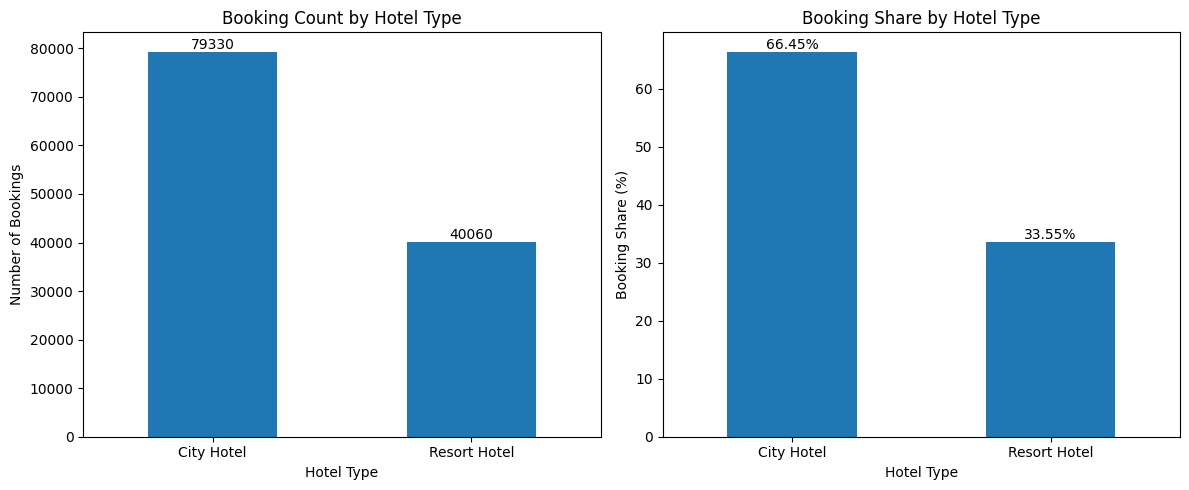

In [ ]:
# Calculate booking count and percentage share
hotel_summary = df["hotel"].value_counts().rename_axis("Hotel").to_frame("Booking Count")
hotel_summary["Booking Share (%)"] = (hotel_summary["Booking Count"] / hotel_summary["Booking Count"].sum() * 100)

# Create two side-by-side bar charts
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Chart 1: Booking Count
hotel_summary["Booking Count"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Booking Count by Hotel Type")
axes[0].set_xlabel("Hotel Type")
axes[0].set_ylabel("Number of Bookings")
axes[0].tick_params(axis="x", rotation=0)

# Add data labels
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f")

# Chart 2: Booking Share
hotel_summary["Booking Share (%)"].plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Booking Share by Hotel Type")
axes[1].set_xlabel("Hotel Type")
axes[1].set_ylabel("Booking Share (%)")
axes[1].tick_params(axis="x", rotation=0)

# Add percentage labels
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.2f%%")

plt.tight_layout()
plt.show()


The dataset contains 119,390 booking records of which 79,330 (66.45%) are associated with City Hotel and 40,060 (33.55%) with Resort Hotel. City Hotel therefore accounts for approximately two-thirds of the recorded bookings.

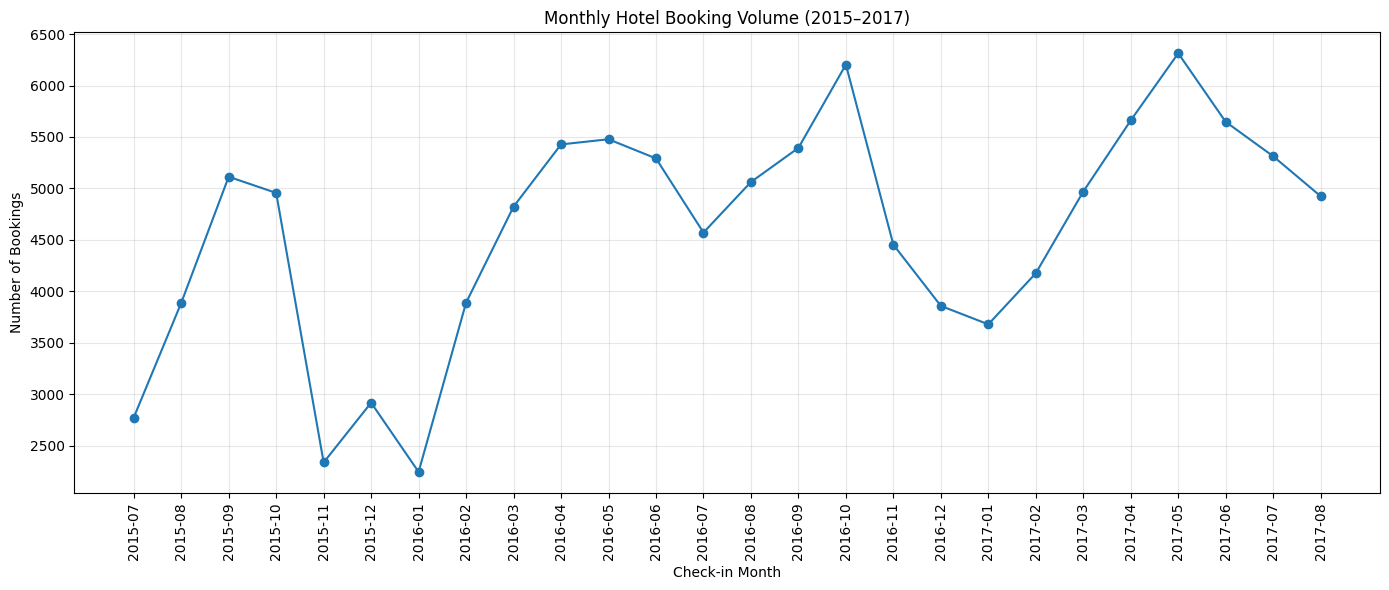

In [ ]:
# Group bookings by check-in month
monthly_bookings = (df.groupby(df["checkin_date"].dt.to_period("M")).size().reset_index(name="booking_count"))

monthly_bookings["month"] = (monthly_bookings["checkin_date"].astype(str))

# Plot the monthly trend
plt.figure(figsize=(14, 6))
plt.plot(
    monthly_bookings["month"],
    monthly_bookings["booking_count"],
    marker="o"
)

plt.title("Monthly Hotel Booking Volume (2015–2017)")
plt.xlabel("Check-in Month")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Findings based on check-in month

- Off-peak period: January 2016 and January 2017 both have relatively low booking volumes.
- Peak period: Booking volume rises towards May in both 2016 and 2017

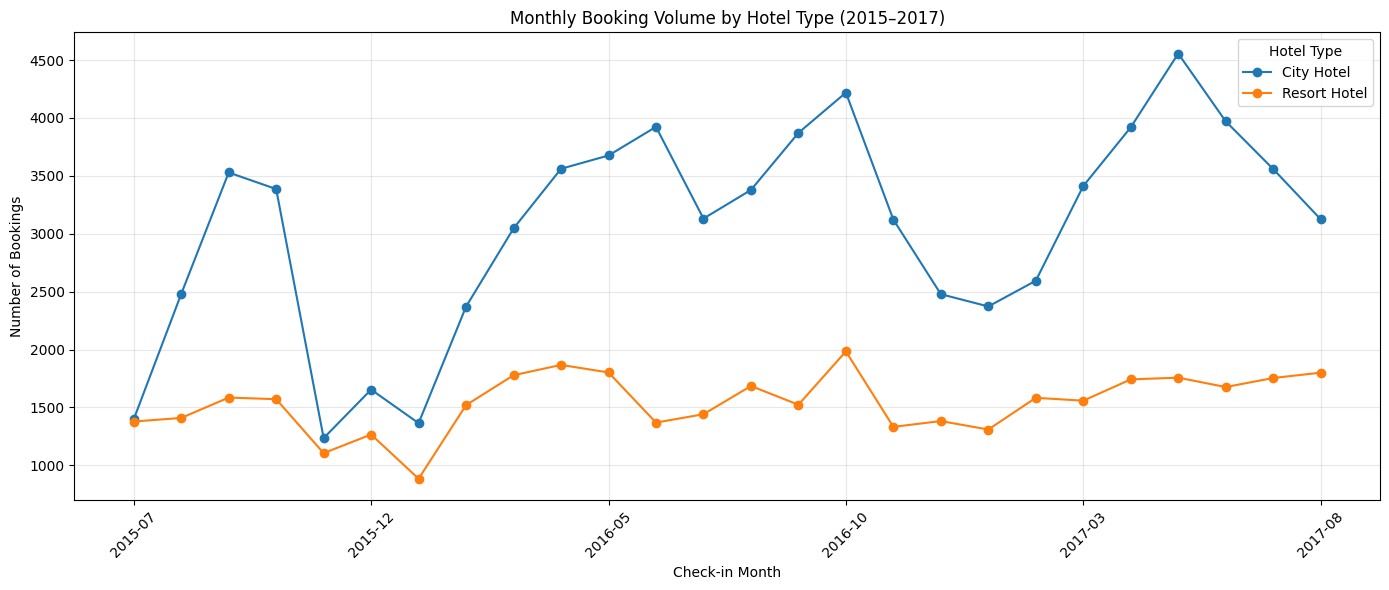

In [ ]:
# Group bookings by month and hotel type
hotel_monthly = (df.groupby([df["checkin_date"].dt.to_period("M"),"hotel"]).size().reset_index(name="booking_count"))

# Rename the date column and convert to string
hotel_monthly = hotel_monthly.rename(columns={"checkin_date": "month"})

hotel_monthly["month"] = hotel_monthly["month"].astype(str)

# Pivot for plotting
hotel_pivot = hotel_monthly.pivot(
    index="month",
    columns="hotel",
    values="booking_count"
).fillna(0)

# Plot
hotel_pivot.plot(figsize=(14, 6), marker="o")

plt.title("Monthly Booking Volume by Hotel Type (2015–2017)")
plt.xlabel("Check-in Month")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.legend(title="Hotel Type")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


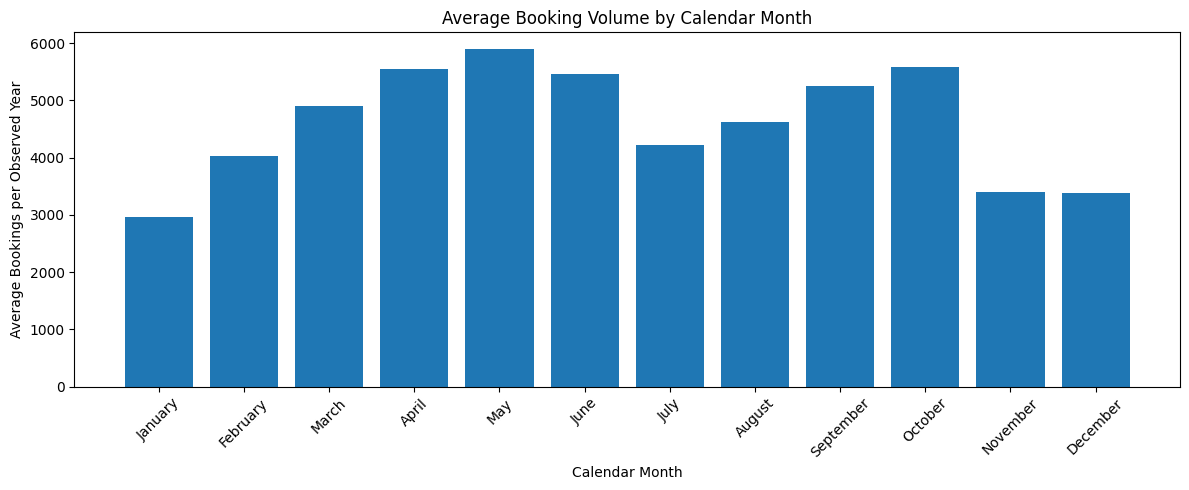

In [ ]:
# Extract calendar month and year
df["year"] = df["checkin_date"].dt.year
df["month_name"] = df["checkin_date"].dt.month_name()
df["month_num"] = df["checkin_date"].dt.month

# Count bookings by year and calendar month
monthly_comparison = (df.groupby(["year", "month_num", "month_name"]).size().reset_index(name="booking_count")
)

# Calculate average monthly booking volume for each calendar month
seasonal_summary = (monthly_comparison.groupby(["month_num", "month_name"])["booking_count"].mean().reset_index(name="avg_bookings").sort_values("month_num"))

# Plot
plt.figure(figsize=(12, 5))

plt.bar(
    seasonal_summary["month_name"],
    seasonal_summary["avg_bookings"]
)

plt.title("Average Booking Volume by Calendar Month")
plt.xlabel("Calendar Month")
plt.ylabel("Average Bookings per Observed Year")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


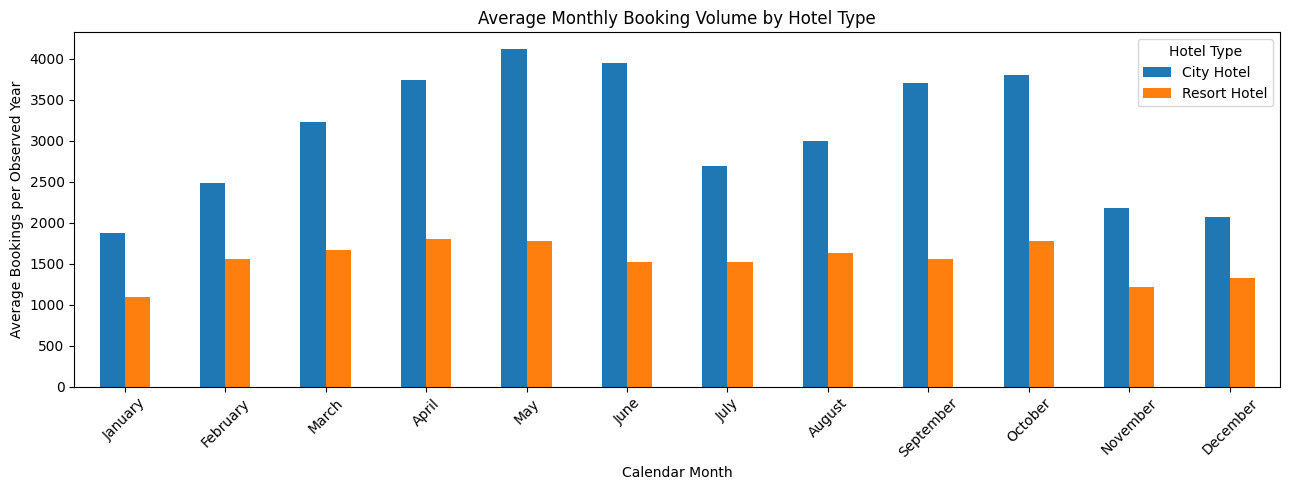

In [ ]:
# Count bookings by year, month and hotel type
hotel_seasonal = (df.groupby(["year", "month_num", "month_name", "hotel"]).size().reset_index(name="booking_count"))

# Average monthly bookings by hotel type
hotel_seasonal_avg = (hotel_seasonal.groupby(["month_num", "month_name", "hotel"])["booking_count"].mean().reset_index())

# Reshape for grouped bar chart
hotel_seasonal_pivot = hotel_seasonal_avg.pivot(
    index="month_name",
    columns="hotel",
    values="booking_count"
).reindex(seasonal_summary["month_name"])

hotel_seasonal_pivot.plot(
    kind="bar",
    figsize=(13, 5)
)

plt.title("Average Monthly Booking Volume by Hotel Type")
plt.xlabel("Calendar Month")
plt.ylabel("Average Bookings per Observed Year")
plt.xticks(rotation=45)
plt.legend(title="Hotel Type")
plt.tight_layout()
plt.show()


May has the highest average booking volume in your overall chart driven largely by City Hotel while resort Hotel also records relatively high bookings around April and May.

November and December have relatively low average booking volumes particularly for City Hotel. Resort Hotel also experiences lower volumes in November.

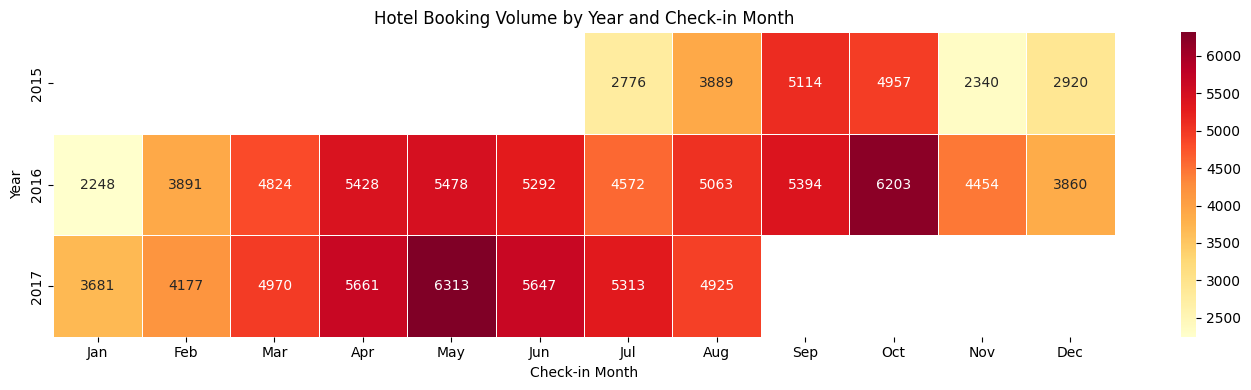

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract year and month from check-in date
df["year"] = df["checkin_date"].dt.year
df["month_num"] = df["checkin_date"].dt.month
df["month_name"] = df["checkin_date"].dt.month_name()

# Count bookings by year and month
monthly_counts = (
    df.groupby(["year", "month_num", "month_name"])
      .size()
      .reset_index(name="booking_count")
)

# Reshape data into a year-by-month matrix
heatmap_data = monthly_counts.pivot(
    index="year",
    columns="month_num",
    values="booking_count"
)

# Ensure months are displayed in calendar order
heatmap_data = heatmap_data.reindex(columns=range(1, 13))

# Use month names as column labels
heatmap_data.columns = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# Plot heatmap
plt.figure(figsize=(14, 4))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5,
    mask=heatmap_data.isna()
)

plt.title("Hotel Booking Volume by Year and Check-in Month")
plt.xlabel("Check-in Month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()


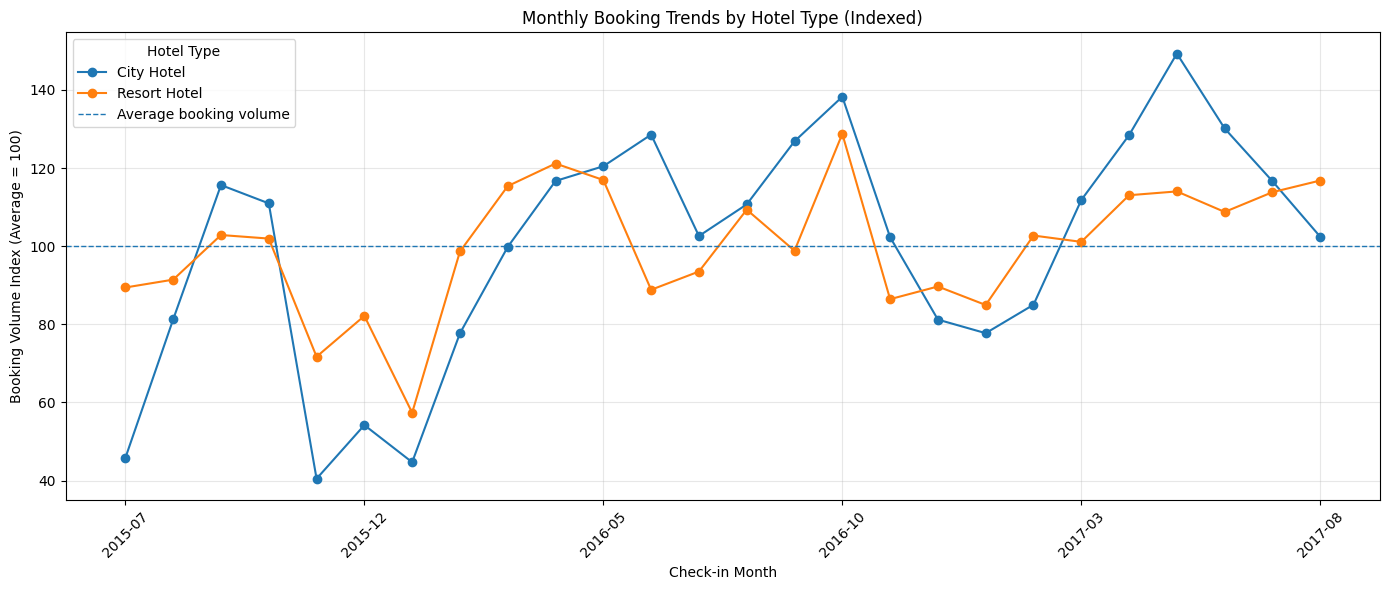

In [ ]:

# Aggregate monthly bookings by hotel type
hotel_monthly = (
    df.groupby([
        df["checkin_date"].dt.to_period("M"),
        "hotel"
    ])
    .size()
    .reset_index(name="booking_count")
)

hotel_monthly = hotel_monthly.rename(
    columns={"checkin_date": "month"}
)

# Pivot so each hotel has its own column
hotel_pivot = hotel_monthly.pivot(
    index="month",
    columns="hotel",
    values="booking_count"
).fillna(0)

# Normalise each hotel's monthly bookings
hotel_index = hotel_pivot.div(
    hotel_pivot.mean(axis=0)
) * 100

# Convert monthly index to readable labels
hotel_index.index = hotel_index.index.astype(str)

# Plot relative seasonal patterns
ax = hotel_index.plot(
    figsize=(14, 6),
    marker="o"
)

ax.axhline(
    100,
    linestyle="--",
    linewidth=1,
    label="Average booking volume"
)

plt.title("Monthly Booking Trends by Hotel Type (Indexed)")
plt.xlabel("Check-in Month")
plt.ylabel("Booking Volume Index (Average = 100)")
plt.xticks(rotation=45)
plt.legend(title="Hotel Type")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
july_2015_city = df[
    (df["checkin_date"].dt.to_period("M") == "2015-07") &
    (df["hotel"] == "City Hotel")
]

print("Total bookings:", len(july_2015_city))
print(
    "Cancelled bookings:",
    (july_2015_city["reservation_status"].str.lower() == "canceled").sum()
)

Total bookings: 1398
Cancelled bookings: 918


In [ ]:
overall_cancellation_rate = (
    df["reservation_status"]
    .str.strip()
    .str.lower()
    .eq("canceled")
    .mean() * 100
)

print(f"Overall cancellation rate: {overall_cancellation_rate:.2f}%")

Overall cancellation rate: 36.03%


# Redo based on revised problem statement

In [ ]:
def cancellation_summary(data, column):
    summary = (
        data.groupby(column, dropna=False)
        .agg(
            total_bookings=("is_canceled", "size"),
            cancelled_bookings=("is_canceled", "sum")
        )
        .reset_index()
    )

    summary["cancellation_rate"] = (
        summary["cancelled_bookings"]
        / summary["total_bookings"] * 100
    )

    summary["booking_share"] = (
        summary["total_bookings"] / len(data) * 100
    )

    return summary.sort_values(
        "cancellation_rate", ascending=False
    )

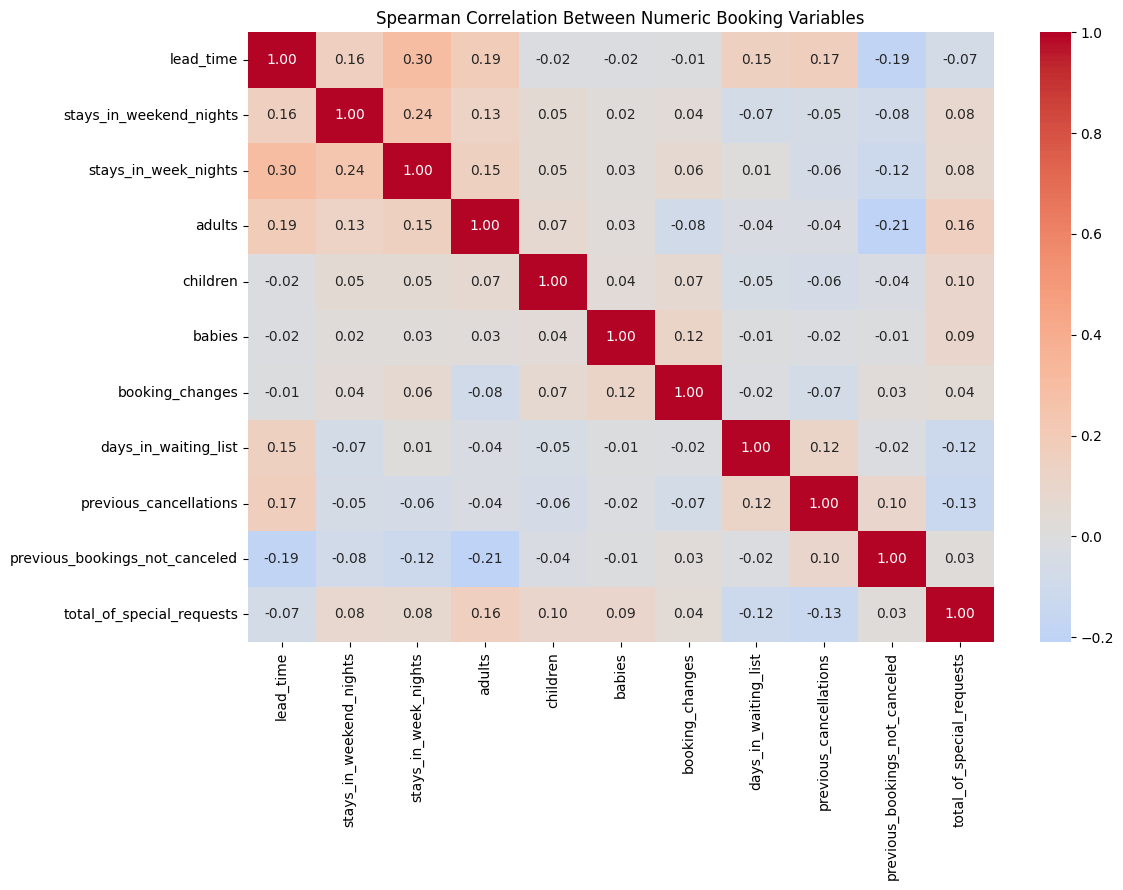

In [ ]:
numeric_cols = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "booking_changes",
    "days_in_waiting_list",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "total_of_special_requests"
]

# Keep only columns available in your dataset
numeric_cols = [col for col in numeric_cols if col in df.columns]

corr_matrix = df[numeric_cols].corr(method="spearman")

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Spearman Correlation Between Numeric Booking Variables")
plt.tight_layout()
plt.show()


#### Additional Chart: Monthly Cancellation Rate by Hotel type

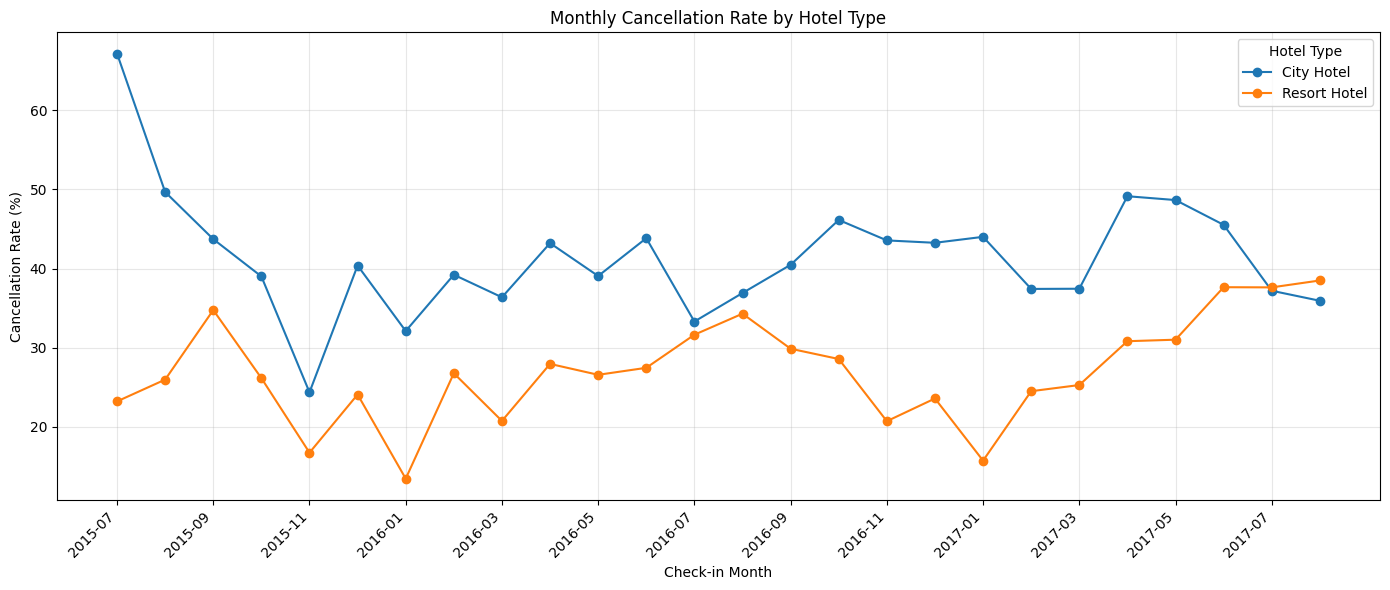

In [ ]:
monthly_cancellation = (
    df.dropna(subset=["checkin_date"])
      .assign(year_month=lambda data: data["checkin_date"].dt.to_period("M"))
      .groupby(["year_month", "hotel"], as_index=False)
      .agg(
          total_bookings=("is_canceled", "size"),
          cancelled_bookings=("is_canceled", "sum"),
      )
)

monthly_cancellation["cancellation_rate"] = (
    monthly_cancellation["cancelled_bookings"]
    / monthly_cancellation["total_bookings"] * 100
)

cancellation_pivot = monthly_cancellation.pivot(
    index="year_month",
    columns="hotel",
    values="cancellation_rate"
).sort_index()

cancellation_pivot.index = cancellation_pivot.index.astype(str)

ax = cancellation_pivot.plot(figsize=(14, 6), marker="o")

tick_positions = list(range(0, len(cancellation_pivot), 2))
ax.set_xticks(tick_positions)
ax.set_xticklabels(
    cancellation_pivot.index[tick_positions],
    rotation=45,
    ha="right"
)

plt.title("Monthly Cancellation Rate by Hotel Type")
plt.xlabel("Check-in Month")
plt.ylabel("Cancellation Rate (%)")
plt.legend(title="Hotel Type")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### RO1: Analyse reservation volumes and cancellation rates by hotel, arrival period, market segment, and distribution channel

#### Cancellation rate by hotel type

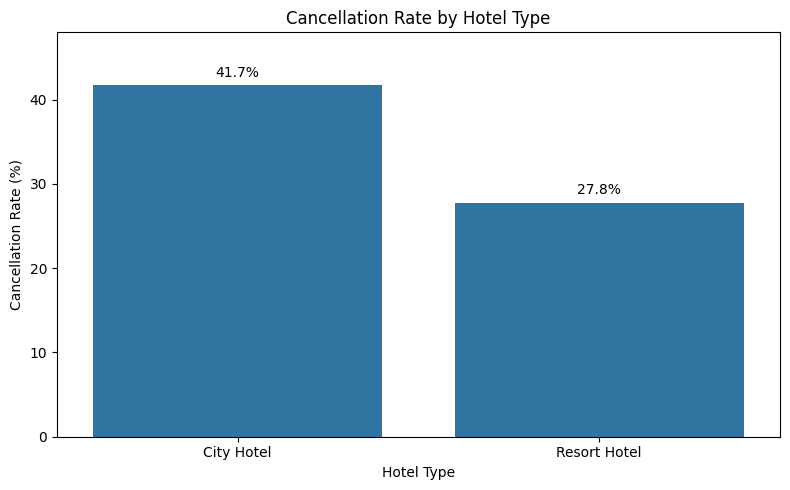

       hotel  total_bookings  cancelled_bookings  cancellation_rate
  City Hotel           79330               33102              41.73
Resort Hotel           40060               11122              27.76


In [ ]:
hotel_summary = cancellation_summary(df, "hotel")

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=hotel_summary,
    x="hotel",
    y="cancellation_rate"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=4)

plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")
plt.ylim(0, hotel_summary["cancellation_rate"].max() * 1.15)
plt.tight_layout()
plt.show()

print(
    hotel_summary[
        ["hotel", "total_bookings",
         "cancelled_bookings", "cancellation_rate"]
    ].round(2).to_string(index=False)
)

Finding 1: City Hotel has a higher cancellation rate
City Hotel's cancellation rate is 40.57% compared with 27.04% for Resort Hotel. This is a difference of 13.53 percentage points.

#### Cancellation rate by arrival month

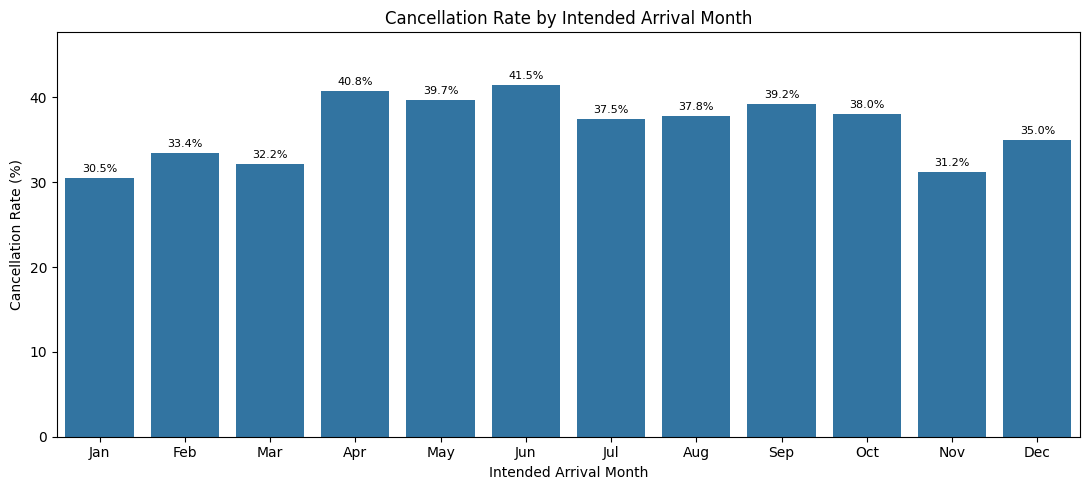

arrival_month  total_bookings  cancelled_bookings  cancellation_rate
          Jan            5929                1807              30.48
          Feb            8068                2696              33.42
          Mar            9794                3149              32.15
          Apr           11089                4524              40.80
          May           11791                4677              39.67
          Jun           10939                4535              41.46
          Jul           12661                4742              37.45
          Aug           13877                5239              37.75
          Sep           10508                4116              39.17
          Oct           11160                4246              38.05
          Nov            6794                2122              31.23
          Dec            6780                2371              34.97


In [ ]:
monthly_data = df.dropna(subset=["checkin_date"]).copy()

monthly_data["arrival_month_num"] = (
    monthly_data["checkin_date"].dt.month
)

monthly_data["arrival_month"] = (
    monthly_data["checkin_date"].dt.strftime("%b")
)

monthly_summary = (
    monthly_data
    .groupby(["arrival_month_num", "arrival_month"])
    .agg(
        total_bookings=("is_canceled", "size"),
        cancelled_bookings=("is_canceled", "sum")
    )
    .reset_index()
)

monthly_summary["cancellation_rate"] = (
    monthly_summary["cancelled_bookings"]
    / monthly_summary["total_bookings"] * 100
)

monthly_summary = monthly_summary.sort_values(
    "arrival_month_num"
)

plt.figure(figsize=(11, 5))

ax = sns.barplot(
    data=monthly_summary,
    x="arrival_month",
    y="cancellation_rate",
    order=monthly_summary["arrival_month"].tolist()
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=8)

plt.title("Cancellation Rate by Intended Arrival Month")
plt.xlabel("Intended Arrival Month")
plt.ylabel("Cancellation Rate (%)")
plt.ylim(0, monthly_summary["cancellation_rate"].max() * 1.15)
plt.tight_layout()
plt.show()

print(
    monthly_summary[
        ["arrival_month", "total_bookings",
         "cancelled_bookings", "cancellation_rate"]
    ].round(2).to_string(index=False)
)

Finding 2: Cancellation rates vary by arrival month
June has the highest rate shown, at 40.7% followed by April at 40.1%. January is lowest at 29.2%, with November at 30.1%.
This suggests that cancellation risk may vary across arrival periods.

#### Cancellation rate by market segment

Full market-segment summary:
market_segment  total_bookings  cancelled_bookings  cancellation_rate
     Undefined               2                   2             100.00
        Groups           19811               12097              61.06
     Online TA           56477               20739              36.72
 Offline TA/TO           24219                8311              34.32
      Aviation             237                  52              21.94
     Corporate            5295                 992              18.73
        Direct           12606                1934              15.34
 Complementary             743                  97              13.06


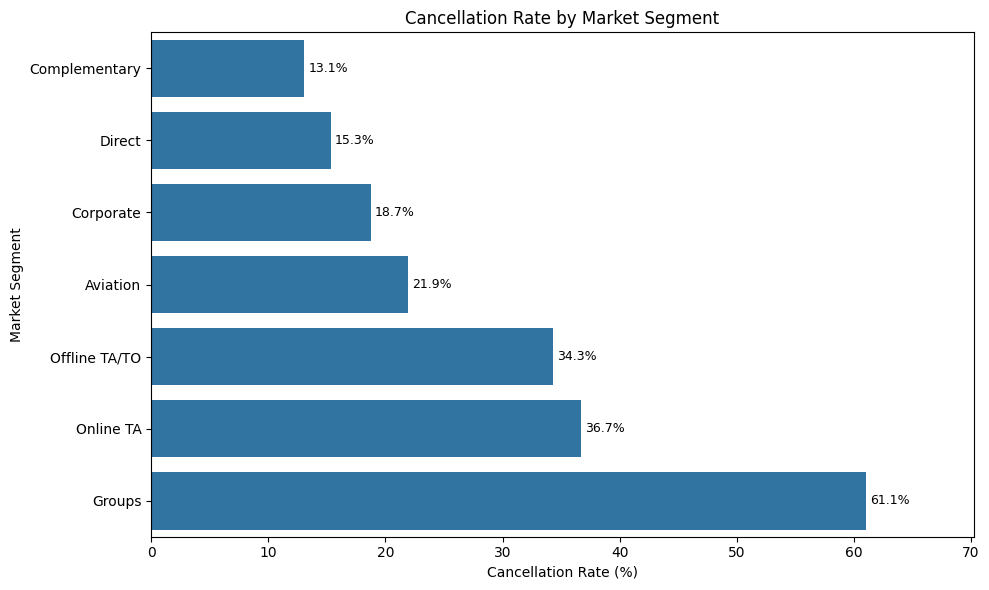

In [ ]:
segment_summary = cancellation_summary(df, "market_segment")

# Check the Undefined category and its sample size
print("Full market-segment summary:")
print(
    segment_summary[
        ["market_segment", "total_bookings",
         "cancelled_bookings", "cancellation_rate"]
    ].round(2).to_string(index=False)
)

# Exclude only the literal Undefined label from the chart
segment_chart = segment_summary[
    segment_summary["market_segment"]
    .astype("string").str.strip().str.lower()
    .ne("undefined")
    .fillna(True)
].copy()

segment_chart = segment_chart.sort_values("cancellation_rate")

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=segment_chart,
    y="market_segment",
    x="cancellation_rate"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)

plt.title("Cancellation Rate by Market Segment")
plt.xlabel("Cancellation Rate (%)")
plt.ylabel("Market Segment")
plt.xlim(0, segment_chart["cancellation_rate"].max() * 1.15)
plt.tight_layout()
plt.show()

Finding 3: Group bookings show a high cancellation rate
The Groups market segment has a cancellation rate of 60.7% while Online TA is 35.7% and Direct is 13.7%.

#### Cancellation rate by distribution channel

Full distribution-channel summary:
distribution_channel  total_bookings  cancelled_bookings  cancellation_rate
           Undefined               5                   4              80.00
               TA/TO           97870               40152              41.03
           Corporate            6677                1474              22.08
                 GDS             193                  37              19.17
              Direct           14645                2557              17.46


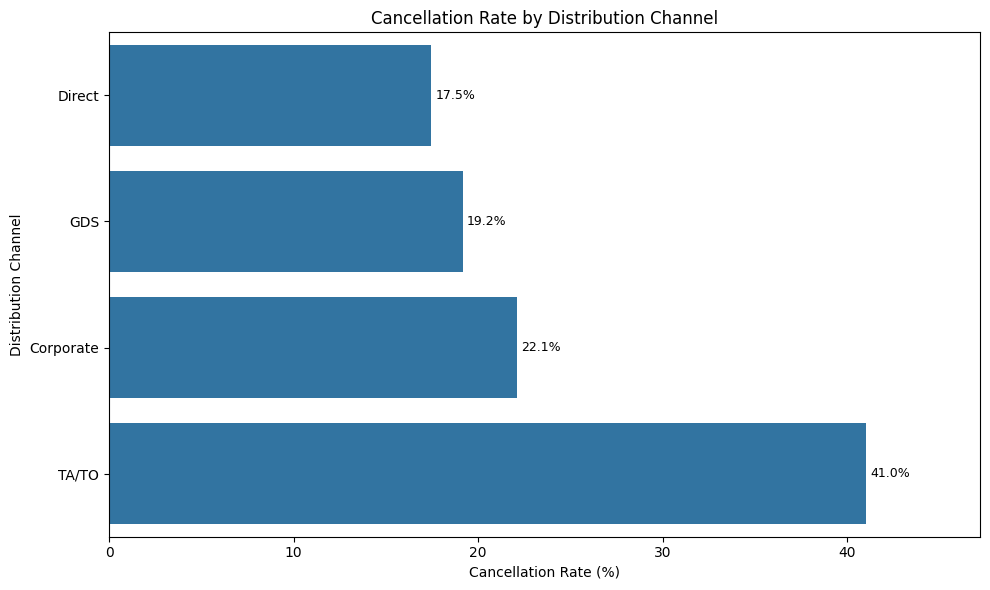

In [ ]:
channel_summary = cancellation_summary(
    df, "distribution_channel"
)

print("Full distribution-channel summary:")
print(
    channel_summary[
        ["distribution_channel", "total_bookings",
         "cancelled_bookings", "cancellation_rate"]
    ].round(2).to_string(index=False)
)

# Exclude Undefined from the main chart if it has fewer than 10 bookings
channel_chart = channel_summary.copy()

undefined_mask = (
    channel_chart["distribution_channel"]
    .astype("string").str.strip().str.lower()
    .eq("undefined")
    .fillna(False)
)

small_undefined = (
    channel_chart.loc[undefined_mask, "total_bookings"] < 10
).any()

if small_undefined:
    channel_chart = channel_chart.loc[~undefined_mask].copy()

channel_chart = channel_chart.sort_values("cancellation_rate")

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=channel_chart,
    y="distribution_channel",
    x="cancellation_rate"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)

plt.title("Cancellation Rate by Distribution Channel")
plt.xlabel("Cancellation Rate (%)")
plt.ylabel("Distribution Channel")
plt.xlim(0, channel_chart["cancellation_rate"].max() * 1.15)
plt.tight_layout()
plt.show()

Finding 4: TA/TO has the highest cancellation rate among the named distribution channels
Travel agents and tour operators (TA/TO) have a rate of 40.1% compared with 20.7% for Corporate, 17.6% for GDS and 15.9% for Direct.

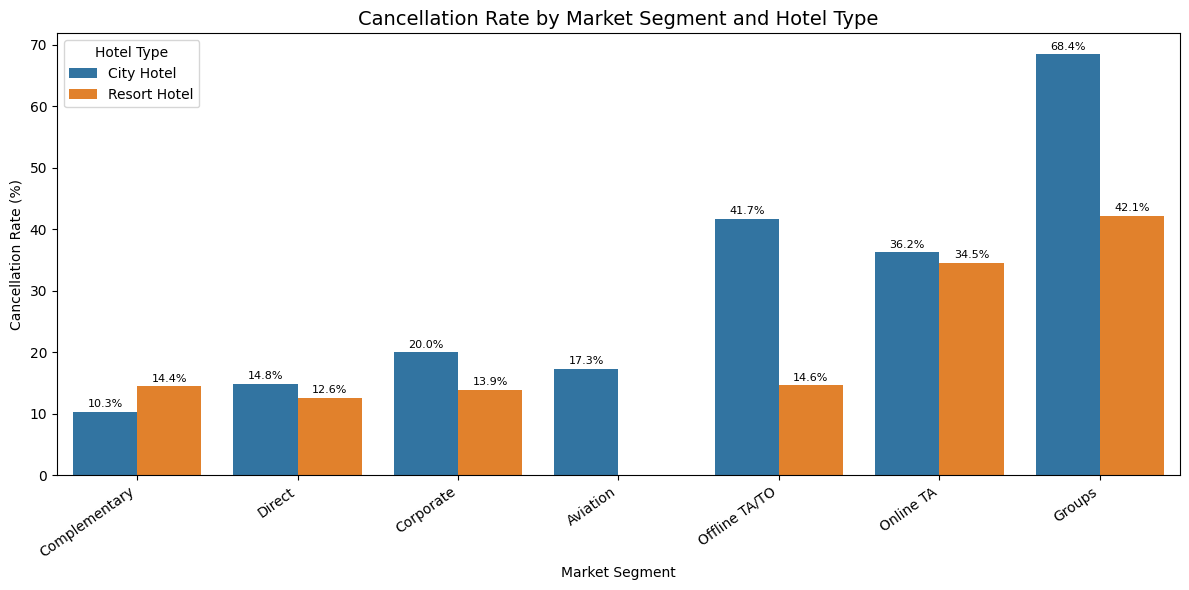

       hotel market_segment  total_bookings  cancelled_bookings  cancellation_rate
  City Hotel       Aviation             237                  41              17.30
  City Hotel  Complementary             542                  56              10.33
Resort Hotel  Complementary             201                  29              14.43
  City Hotel      Corporate            2986                 596              19.96
Resort Hotel      Corporate            2309                 320              13.86
  City Hotel         Direct            6093                 904              14.84
Resort Hotel         Direct            6513                 818              12.56
  City Hotel         Groups           13975                9564              68.44
Resort Hotel         Groups            5836                2459              42.14
  City Hotel  Offline TA/TO           16747                6989              41.73
Resort Hotel  Offline TA/TO            7472                1091              14.60
  Ci

In [ ]:
# Create cancellation flag if not already created
df["is_cancelled"] = (
    df["reservation_status"]
    .astype(str).str.strip().str.lower()
    .eq("canceled")
)

# Calculate booking volume and cancellation rate
segment_hotel = (
    df.groupby(["hotel", "market_segment"], dropna=False)
      .agg(
          total_bookings=("is_cancelled", "size"),
          cancelled_bookings=("is_cancelled", "sum")
      )
      .reset_index()
)

segment_hotel["cancellation_rate"] = (
    segment_hotel["cancelled_bookings"]
    / segment_hotel["total_bookings"] * 100
)

# Exclude Undefined from the chart
segment_hotel["segment_clean"] = (
    segment_hotel["market_segment"]
    .astype("string").str.strip()
)

plot_data = segment_hotel[
    segment_hotel["segment_clean"].str.lower()
    .ne("undefined").fillna(True)
].copy()

# Sort segments by overall cancellation rate
segment_order = (
    plot_data.groupby("market_segment")
    .apply(
        lambda x: (
            x["cancelled_bookings"].sum()
            / x["total_bookings"].sum() * 100
        ),
        include_groups=False
    )
    .sort_values()
    .index.tolist()
)

# Plot grouped bars
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=plot_data,
    x="market_segment",
    y="cancellation_rate",
    hue="hotel",
    order=segment_order
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=2,
        fontsize=8
    )

plt.title(
    "Cancellation Rate by Market Segment and Hotel Type",
    fontsize=14
)
plt.xlabel("Market Segment")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Hotel Type")
plt.tight_layout()
plt.show()

# Print the supporting figures
print(
    plot_data[
        ["hotel", "market_segment", "total_bookings",
         "cancelled_bookings", "cancellation_rate"]
    ]
    .sort_values(["market_segment", "hotel"])
    .round(2)
    .to_string(index=False)
)


Finding 5:
Highest cancellation come from City Hotel with cancellation for group at 68.44% and online TA with 14,034 cancellations.

In [ ]:
print(
    segment_hotel[
        [
            "hotel",
            "market_segment",
            "total_bookings",
            "cancelled_bookings",
            "cancellation_rate"
        ]
    ]
    .sort_values(
        "cancellation_rate",
        ascending=False
    )
    .round(2)
    .to_string(index=False)
)

       hotel market_segment  total_bookings  cancelled_bookings  cancellation_rate
  City Hotel      Undefined               2                   2             100.00
  City Hotel         Groups           13975                9564              68.44
Resort Hotel         Groups            5836                2459              42.14
  City Hotel  Offline TA/TO           16747                6989              41.73
  City Hotel      Online TA           38748               14034              36.22
Resort Hotel      Online TA           17729                6114              34.49
  City Hotel      Corporate            2986                 596              19.96
  City Hotel       Aviation             237                  41              17.30
  City Hotel         Direct            6093                 904              14.84
Resort Hotel  Offline TA/TO            7472                1091              14.60
Resort Hotel  Complementary             201                  29              14.43
Reso

### RO2: Identify booking characteristics associated with cancellation, including lead time, deposit type, customer type, stay length, party composition, booking changes, and special requests.

#### Cancellation rate by lead-time group

count    119390.000000
mean        104.011416
std         106.863097
min           0.000000
25%          18.000000
50%          69.000000
75%         160.000000
max         737.000000
Name: lead_time, dtype: float64
Missing lead_time values: 0


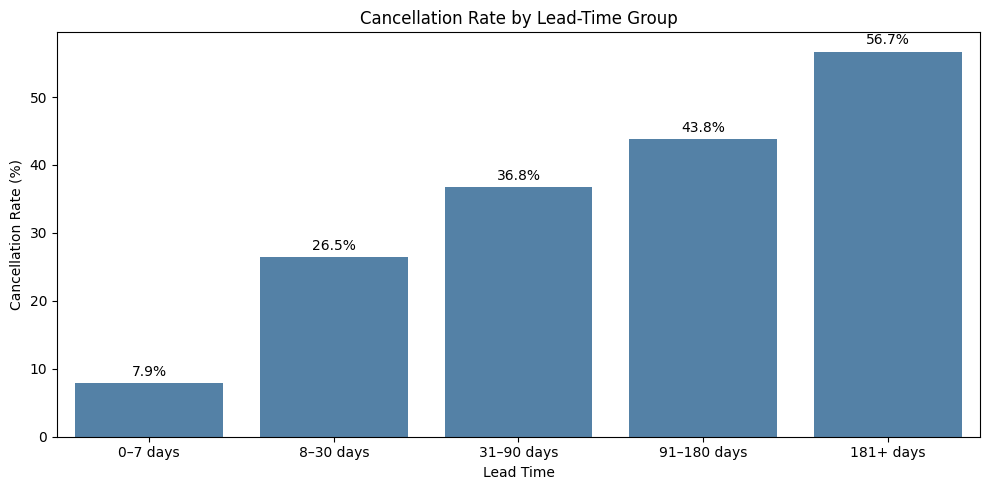

lead_time_group  total_bookings  cancelled_bookings  cancellation_rate
       0–7 days           19746                1555               7.88
      8–30 days           18960                5018              26.47
     31–90 days           29553               10876              36.80
    91–180 days           26439               11569              43.76
      181+ days           24692               13999              56.69


In [ ]:
# Check lead_time data
print(df["lead_time"].describe())
print("Missing lead_time values:", df["lead_time"].isna().sum())

# Create lead-time groups
bins = [-1, 7, 30, 90, 180, float("inf")]
labels = [
    "0–7 days",
    "8–30 days",
    "31–90 days",
    "91–180 days",
    "181+ days"
]

df["lead_time_group"] = pd.cut(
    df["lead_time"],
    bins=bins,
    labels=labels
)

# Summarise booking volume and cancellation rate
lead_summary = (
    df.dropna(subset=["lead_time_group"])
      .groupby("lead_time_group", observed=False)
      .agg(
          total_bookings=("is_cancelled", "size"),
          cancelled_bookings=("is_cancelled", "sum")
      )
      .reset_index()
)

lead_summary["cancellation_rate"] = (
    lead_summary["cancelled_bookings"]
    / lead_summary["total_bookings"] * 100
)

# Plot cancellation rate
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=lead_summary,
    x="lead_time_group",
    y="cancellation_rate",
    color="steelblue"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Cancellation Rate by Lead-Time Group")
plt.xlabel("Lead Time")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()

# Display the figures supporting the chart
print(
    lead_summary[
        ["lead_time_group", "total_bookings",
         "cancelled_bookings", "cancellation_rate"]
    ].round(2).to_string(index=False)
)


Observation: The cancellation rate increases with each successive lead-time band. The longest lead-time group has a cancellation rate about 7.2 times that of the 0–7-day group. 56.69% bookings made 181 days or more before arrival were cancelled

### Compare lead time by cancellation outcome

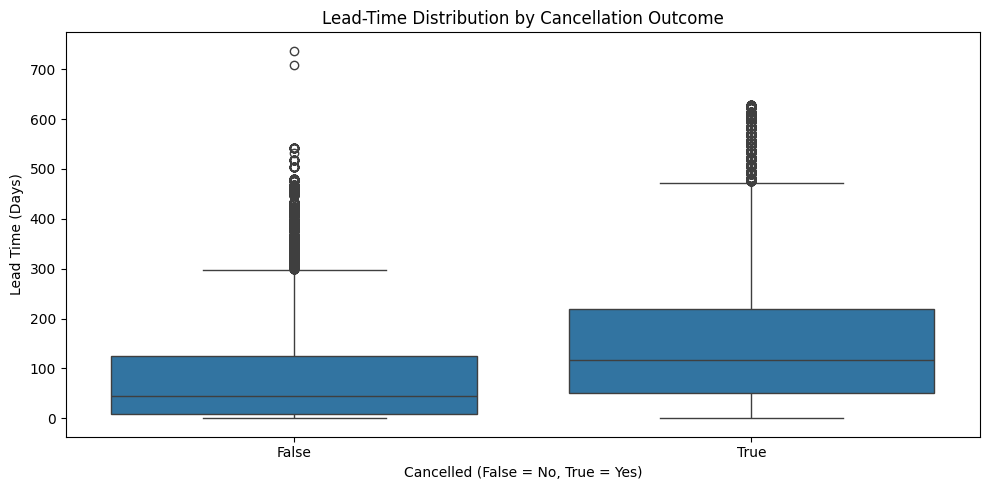

In [ ]:

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df.dropna(subset=["lead_time"]),
    x="is_cancelled",
    y="lead_time"
)

plt.title("Lead-Time Distribution by Cancellation Outcome")
plt.xlabel("Cancelled (False = No, True = Yes)")
plt.ylabel("Lead Time (Days)")
plt.tight_layout()
plt.show()


The boxplot further indicates that cancelled bookings generally had longer lead times than non-cancelled bookings. These findings suggest that lead time may be a useful indicator of cancellation risk and should be considered in further analysis and predictive modelling.

In [ ]:
df.groupby("is_cancelled")["lead_time"].median()

,lead_time
is_cancelled,
False,45.0
True,116.0


### Cancellation rate by deposit type

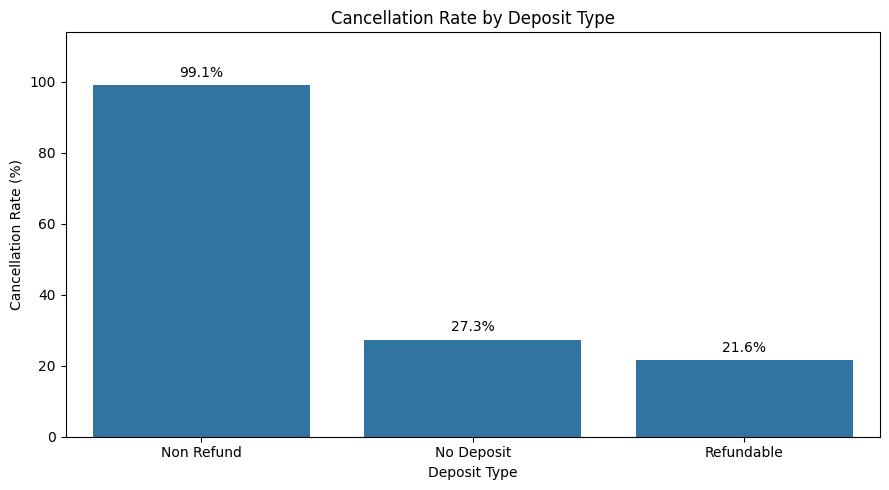

deposit_type  total_bookings  cancelled_bookings  cancellation_rate
  Non Refund           14587               14460              99.13
  No Deposit          104641               28522              27.26
  Refundable             162                  35              21.60


In [ ]:

# Summarise cancellation rate by deposit type
deposit_summary = (
    df.groupby("deposit_type", dropna=False)
      .agg(
          total_bookings=("is_cancelled", "size"),
          cancelled_bookings=("is_cancelled", "sum")
      )
      .reset_index()
)

deposit_summary["cancellation_rate"] = (
    deposit_summary["cancelled_bookings"]
    / deposit_summary["total_bookings"] * 100
)

deposit_summary = deposit_summary.sort_values(
    "cancellation_rate", ascending=False
)

# Plot cancellation rate
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=deposit_summary,
    x="deposit_type",
    y="cancellation_rate"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=4)

plt.title("Cancellation Rate by Deposit Type")
plt.xlabel("Deposit Type")
plt.ylabel("Cancellation Rate (%)")
plt.ylim(0, deposit_summary["cancellation_rate"].max() * 1.15)
plt.tight_layout()
plt.show()

# Print supporting counts
print(
    deposit_summary[
        ["deposit_type", "total_bookings",
         "cancelled_bookings", "cancellation_rate"]
    ].round(2).to_string(index=False)
)


Observation: 99.13% cancellation come from non-refund deposit type which is very strange

In [ ]:

# Check the raw reservation outcomes for each deposit type
deposit_check = pd.crosstab(
    df["deposit_type"],
    df["reservation_status"],
    margins=True
)

print(deposit_check)

# Calculate cancellation rates directly from the raw records
print("\nCancellation rates by deposit type:")

print(
    df.groupby("deposit_type", dropna=False)
      .agg(
          total_bookings=("reservation_status", "size"),
          cancelled_bookings=(
              "reservation_status",
              lambda s: s.astype(str).str.strip()
                         .str.lower().eq("canceled").sum()
          )
      )
      .assign(
          cancellation_rate=lambda x:
              x["cancelled_bookings"]
              / x["total_bookings"] * 100
      )
      .round(2)
)


reservation_status  Canceled  Check-Out  No-Show     All
deposit_type                                            
No Deposit             28522      74947     1172  104641
Non Refund             14460         93       34   14587
Refundable                35        126        1     162
All                    43017      75166     1207  119390

Cancellation rates by deposit type:
              total_bookings  cancelled_bookings  cancellation_rate
deposit_type                                                       
No Deposit            104641               28522              27.26
Non Refund             14587               14460              99.13
Refundable               162                  35              21.60


In [ ]:

deposit_hotel = (
    df.groupby(["hotel", "deposit_type"], dropna=False)
      .agg(
          total_bookings=("reservation_status", "size"),
          cancelled_bookings=(
              "reservation_status",
              lambda s: s.astype(str).str.strip()
                         .str.lower().eq("canceled").sum()
          )
      )
      .reset_index()
)

deposit_hotel["cancellation_rate"] = (
    deposit_hotel["cancelled_bookings"]
    / deposit_hotel["total_bookings"] * 100
)

print(
    deposit_hotel.sort_values(
        ["deposit_type", "hotel"]
    ).round(2).to_string(index=False)
)


       hotel deposit_type  total_bookings  cancelled_bookings  cancellation_rate
  City Hotel   No Deposit           66442               19344              29.11
Resort Hotel   No Deposit           38199                9178              24.03
  City Hotel   Non Refund           12868               12828              99.69
Resort Hotel   Non Refund            1719                1632              94.94
  City Hotel   Refundable              20                  14              70.00
Resort Hotel   Refundable             142                  21              14.79


In [ ]:

# Inspect all reservation outcomes for City Hotel Non Refund
city_nonrefund = df[
    (df["hotel"] == "City Hotel") &
    (df["deposit_type"] == "Non Refund")
]

print("Number of records:", len(city_nonrefund))

print("\nReservation status:")
print(city_nonrefund["reservation_status"].value_counts(dropna=False))

print("\nDeposit type values:")
print(city_nonrefund["deposit_type"].value_counts(dropna=False))

print("\nReservation status by deposit type:")
print(pd.crosstab(
    city_nonrefund["deposit_type"],
    city_nonrefund["reservation_status"],
    dropna=False
))


Number of records: 12868

Reservation status:
reservation_status
Canceled     12828
Check-Out       24
No-Show         16
Name: count, dtype: int64

Deposit type values:
deposit_type
Non Refund    12868
Name: count, dtype: int64

Reservation status by deposit type:
reservation_status  Canceled  Check-Out  No-Show
deposit_type                                    
Non Refund             12828         24       16


In [ ]:

# Summarise City Hotel outcomes by deposit type
city_deposit_profile = (
    df[df["hotel"] == "City Hotel"]
    .groupby("deposit_type", dropna=False)
    .agg(
        total_bookings=("reservation_status", "size"),
        cancelled=("reservation_status",
                   lambda s: s.eq("Canceled").sum()),
        checked_out=("reservation_status",
                     lambda s: s.eq("Check-Out").sum()),
        no_show=("reservation_status",
                 lambda s: s.eq("No-Show").sum()),
        median_lead_time=("lead_time", "median")
    )
)

city_deposit_profile["cancellation_rate"] = (
    city_deposit_profile["cancelled"]
    / city_deposit_profile["total_bookings"] * 100
)

print(city_deposit_profile.round(2))


              total_bookings  cancelled  checked_out  no_show  \
deposit_type                                                    
No Deposit             66442      19344        46198      900   
Non Refund             12868      12828           24       16   
Refundable                20         14            6        0   

              median_lead_time  cancellation_rate  
deposit_type                                       
No Deposit                59.0              29.11  
Non Refund               188.0              99.69  
Refundable                61.5              70.00  


In [ ]:
city_nonrefund = df[
    (df["hotel"] == "City Hotel") &
    (df["deposit_type"] == "Non Refund")
]

print("Market segment:")
print(city_nonrefund["market_segment"].value_counts(dropna=False))

print("\nCustomer type:")
print(city_nonrefund["customer_type"].value_counts(dropna=False))

print("\nMarket segment by reservation outcome:")
print(pd.crosstab(
    city_nonrefund["market_segment"],
    city_nonrefund["reservation_status"],
    margins=True
))

Market segment:
market_segment
Groups           7660
Offline TA/TO    4855
Corporate         309
Online TA          26
Direct             18
Name: count, dtype: int64

Customer type:
customer_type
Transient          11290
Transient-Party     1038
Contract             540
Name: count, dtype: int64

Market segment by reservation outcome:
reservation_status  Canceled  Check-Out  No-Show    All
market_segment                                         
Corporate                294         15        0    309
Direct                    16          2        0     18
Groups                  7656          4        0   7660
Offline TA/TO           4838          1       16   4855
Online TA                 24          2        0     26
All                    12828         24       16  12868


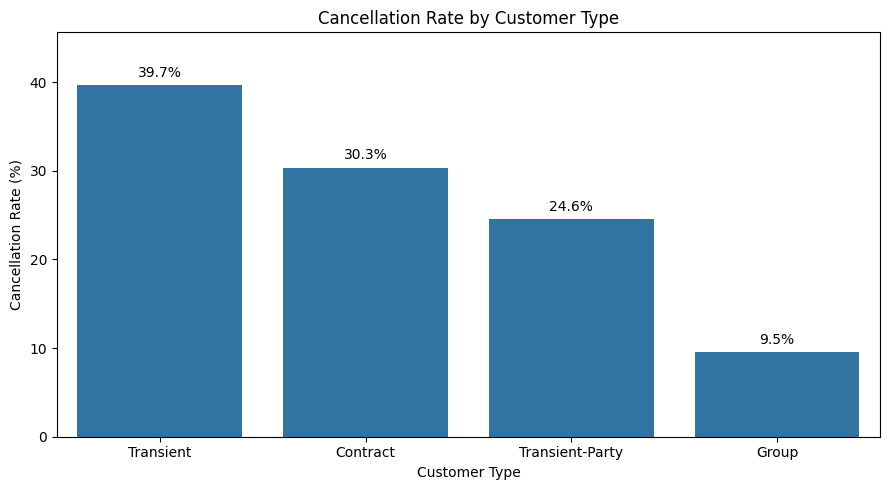

  customer_type  total_bookings  cancelled_bookings  cancellation_rate
      Transient           89613               35557              39.68
       Contract            4076                1236              30.32
Transient-Party           25124                6169              24.55
          Group             577                  55               9.53


In [ ]:

# Cancellation rate by customer type

customer_summary = (
    df.groupby("customer_type", dropna=False)
      .agg(
          total_bookings=("is_cancelled", "size"),
          cancelled_bookings=("is_cancelled", "sum")
      )
      .reset_index()
)

customer_summary["cancellation_rate"] = (
    customer_summary["cancelled_bookings"]
    / customer_summary["total_bookings"] * 100
)

customer_summary = customer_summary.sort_values(
    "cancellation_rate", ascending=False
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=customer_summary,
    x="customer_type",
    y="cancellation_rate"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=4)

plt.title("Cancellation Rate by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Cancellation Rate (%)")
plt.ylim(0, customer_summary["cancellation_rate"].max() * 1.15)
plt.tight_layout()
plt.show()

print(
    customer_summary[
        ["customer_type", "total_bookings",
         "cancelled_bookings", "cancellation_rate"]
    ].round(2).to_string(index=False)
)


How does length of stay affect cancellation rate

In [ ]:

# Calculate total length of stay
df["total_nights"] = (
    df["stays_in_weekend_nights"]
    + df["stays_in_week_nights"]
)

# Check the distribution
print(df["total_nights"].describe())

print(
    "Bookings with zero nights:",
    (df["total_nights"] == 0).sum()
)

# Create stay-length groups
bins = [-1, 0, 3, 7, 14, float("inf")]
labels = [
    "0 nights",
    "1–3 nights",
    "4–7 nights",
    "8–14 nights",
    "15+ nights"
]

df["stay_length_group"] = pd.cut(
    df["total_nights"],
    bins=bins,
    labels=labels
)


count    119390.000000
mean          3.427900
std           2.557439
min           0.000000
25%           2.000000
50%           3.000000
75%           4.000000
max          69.000000
Name: total_nights, dtype: float64
Bookings with zero nights: 715


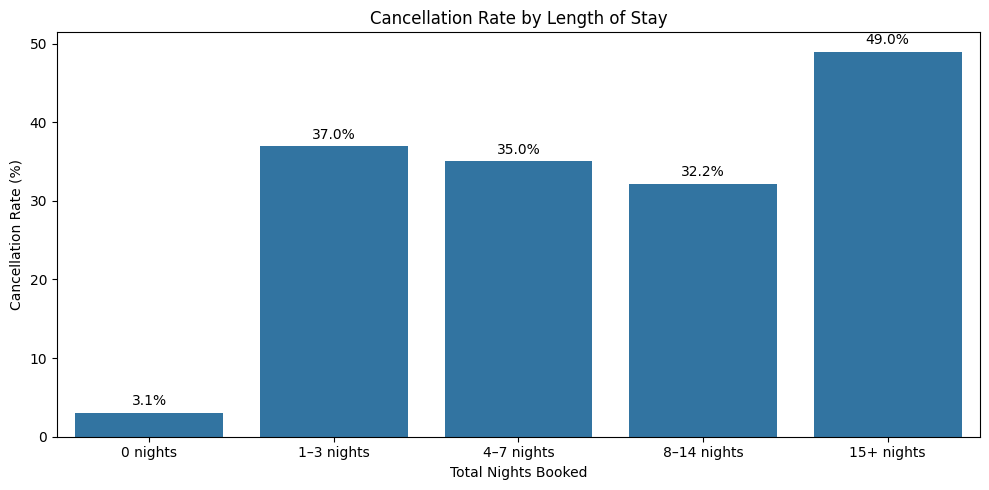

stay_length_group  total_bookings  cancelled_bookings  cancellation_rate
         0 nights             715                  22               3.08
       1–3 nights           75739               28030              37.01
       4–7 nights           37679               13199              35.03
      8–14 nights            4818                1551              32.19
       15+ nights             439                 215              48.97


In [ ]:

stay_summary = (
    df.groupby("stay_length_group", observed=False)
      .agg(
          total_bookings=("is_cancelled", "size"),
          cancelled_bookings=("is_cancelled", "sum")
      )
      .reset_index()
)

stay_summary["cancellation_rate"] = (
    stay_summary["cancelled_bookings"]
    / stay_summary["total_bookings"] * 100
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=stay_summary,
    x="stay_length_group",
    y="cancellation_rate"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Cancellation Rate by Length of Stay")
plt.xlabel("Total Nights Booked")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()

print(
    stay_summary[
        ["stay_length_group", "total_bookings",
         "cancelled_bookings", "cancellation_rate"]
    ].round(2).to_string(index=False)
)


### Relationship Between Length of Stay and Cancellation

The analysis indicates that cancellation rates vary across length-of-stay groups. Reservations for 15 nights or more recorded the highest cancellation rate at 48.97%, while zero-night bookings had the lowest rate at 3.08%. The 1–3 night group accounted for the largest booking volume with 28,030 cancellations from 75,739 reservations.

The results suggest that length of stay may be a useful characteristic to investigate when assessing cancellation risk. However, the relationship is not strictly linear, as cancellation rates decline across the 1–3, 4–7 and 8–14 night groups before increasing for stays of 15 nights or more. Further analysis is required to determine whether these patterns remain after considering other booking characteristics.

#### Cancellation rate by number of booking changes

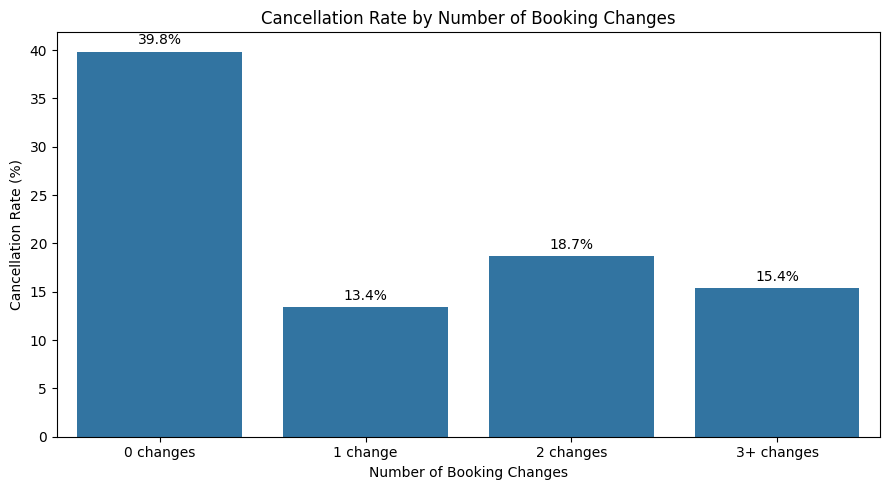

booking_changes_group  total_bookings  cancelled_bookings  cancellation_rate
            0 changes          101314               40361              39.84
             1 change           12701                1702              13.40
            2 changes            3805                 712              18.71
           3+ changes            1570                 242              15.41


In [ ]:

# Group booking changes into readable categories
def group_booking_changes(n):
    if n == 0:
        return "0 changes"
    elif n == 1:
        return "1 change"
    elif n == 2:
        return "2 changes"
    else:
        return "3+ changes"

df["booking_changes_group"] = (
    df["booking_changes"].apply(group_booking_changes)
)

change_order = [
    "0 changes",
    "1 change",
    "2 changes",
    "3+ changes"
]

# Calculate booking volume and cancellation rate
changes_group_summary = (
    df.groupby("booking_changes_group", observed=False)
      .agg(
          total_bookings=("is_cancelled", "size"),
          cancelled_bookings=("is_cancelled", "sum")
      )
      .reindex(change_order)
      .reset_index()
)

changes_group_summary["cancellation_rate"] = (
    changes_group_summary["cancelled_bookings"]
    / changes_group_summary["total_bookings"] * 100
)

# Plot
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=changes_group_summary,
    x="booking_changes_group",
    y="cancellation_rate",
    order=change_order
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Cancellation Rate by Number of Booking Changes")
plt.xlabel("Number of Booking Changes")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()

print(
    changes_group_summary[
        ["booking_changes_group", "total_bookings",
         "cancelled_bookings", "cancellation_rate"]
    ].round(2).to_string(index=False)
)


Group with 0 changes accounts for about 84.9% of all bookings and 40,361 cancellations. It has both the largest booking volume and the highest cancellation rate.

#### Cancellation rate by number of special requests

Missing special requests: 0


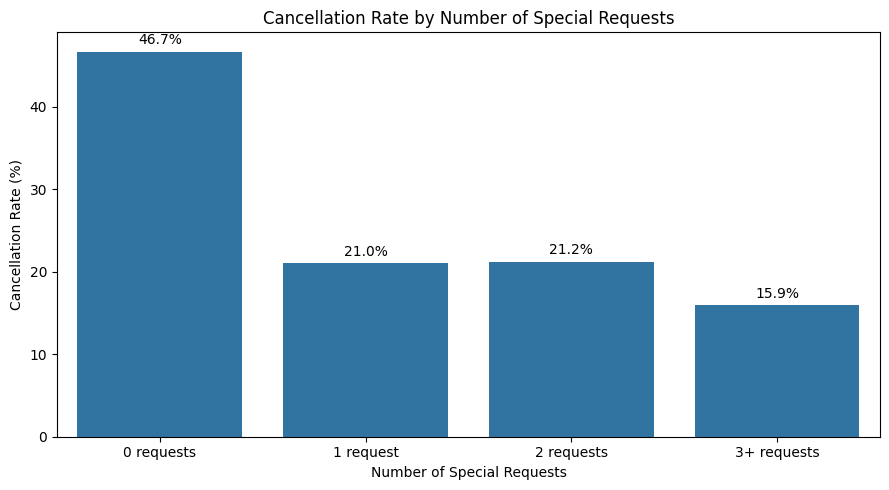

special_requests_group  total_bookings  cancelled_bookings  cancellation_rate
            0 requests           70318               32822              46.68
             1 request           33226                6985              21.02
            2 requests           12969                2752              21.22
           3+ requests            2877                 458              15.92


In [ ]:

# Check whether special requests contain missing values
print(
    "Missing special requests:",
    df["total_of_special_requests"].isna().sum()
)

# Group the number of special requests
def group_special_requests(n):
    if n == 0:
        return "0 requests"
    elif n == 1:
        return "1 request"
    elif n == 2:
        return "2 requests"
    else:
        return "3+ requests"

df["special_requests_group"] = (
    df["total_of_special_requests"].apply(group_special_requests)
)

request_order = [
    "0 requests",
    "1 request",
    "2 requests",
    "3+ requests"
]

requests_summary = (
    df.groupby("special_requests_group")
      .agg(
          total_bookings=("is_cancelled", "size"),
          cancelled_bookings=("is_cancelled", "sum")
      )
      .reindex(request_order)
      .reset_index()
)

requests_summary["cancellation_rate"] = (
    requests_summary["cancelled_bookings"]
    / requests_summary["total_bookings"] * 100
)

# Plot cancellation rate
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=requests_summary,
    x="special_requests_group",
    y="cancellation_rate",
    order=request_order
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Cancellation Rate by Number of Special Requests")
plt.xlabel("Number of Special Requests")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()

print(
    requests_summary[
        ["special_requests_group", "total_bookings",
         "cancelled_bookings", "cancellation_rate"]
    ].round(2).to_string(index=False)
)


#### Cancellation rate by waiting-list days

In [ ]:

print(df["days_in_waiting_list"].describe())

print(
    "\nBookings with zero waiting-list days:",
    (df["days_in_waiting_list"] == 0).sum()
)

print(
    "Bookings with more than zero waiting-list days:",
    (df["days_in_waiting_list"] > 0).sum()
)

print(
    "Missing values:",
    df["days_in_waiting_list"].isna().sum()
)


count    119390.000000
mean          2.321149
std          17.594721
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max         391.000000
Name: days_in_waiting_list, dtype: float64

Bookings with zero waiting-list days: 115692
Bookings with more than zero waiting-list days: 3698
Missing values: 0


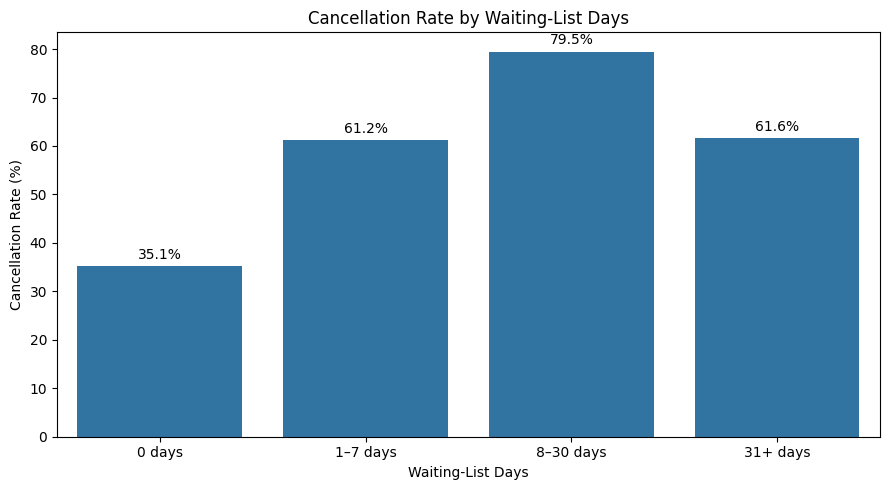

waiting_list_group  total_bookings  cancelled_bookings  cancellation_rate
            0 days          115692               40658              35.14
          1–7 days             129                  79              61.24
         8–30 days             463                 368              79.48
          31+ days            3106                1912              61.56


In [ ]:
# Create waiting-list groups
bins = [-1, 0, 7, 30, float("inf")]
labels = ["0 days", "1–7 days", "8–30 days", "31+ days"]

df["waiting_list_group"] = pd.cut(
    df["days_in_waiting_list"],
    bins=bins,
    labels=labels
)

# Summarise booking volume and cancellations
waiting_summary = (
    df.groupby("waiting_list_group", observed=False)
      .agg(
          total_bookings=("is_cancelled", "size"),
          cancelled_bookings=("is_cancelled", "sum")
      )
      .reset_index()
)

waiting_summary["cancellation_rate"] = (
    waiting_summary["cancelled_bookings"]
    / waiting_summary["total_bookings"] * 100
)

# Visualise cancellation rate
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=waiting_summary,
    x="waiting_list_group",
    y="cancellation_rate",
    order=labels
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Cancellation Rate by Waiting-List Days")
plt.xlabel("Waiting-List Days")
plt.ylabel("Cancellation Rate (%)")
plt.tight_layout()
plt.show()

print(
    waiting_summary[
        ["waiting_list_group", "total_bookings",
         "cancelled_bookings", "cancellation_rate"]
    ].round(2).to_string(index=False)
)


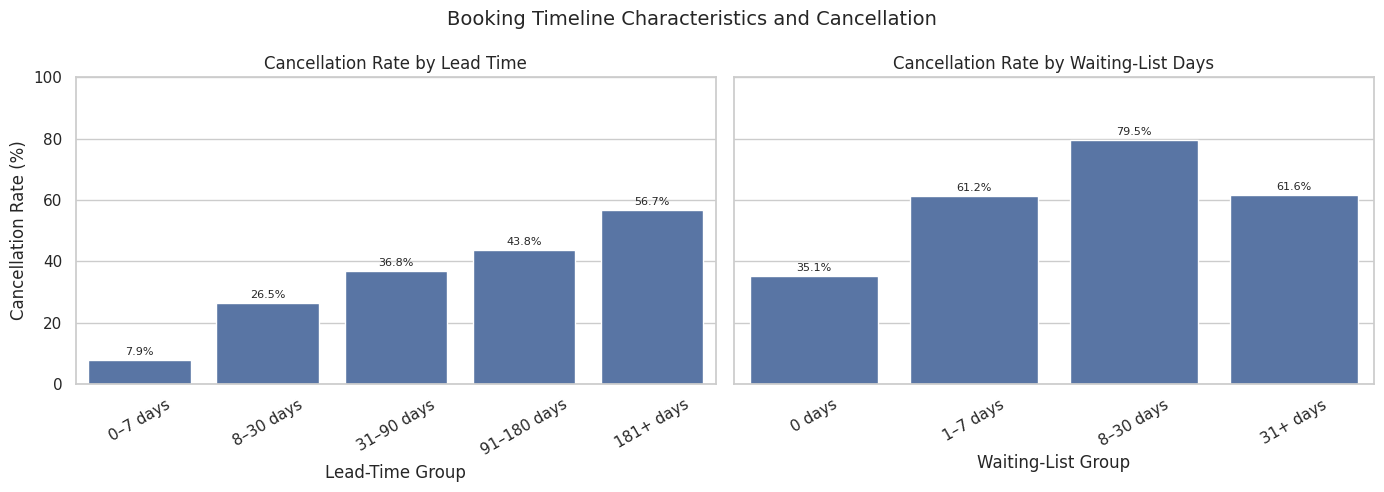

In [ ]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# 1. Cancellation rate by lead time
lead_summary = (
    df.groupby("lead_time_group", observed=False)
      .agg(
          total_bookings=("is_cancelled", "size"),
          cancelled_bookings=("is_cancelled", "sum")
      )
      .reset_index()
)

lead_summary["cancellation_rate"] = (
    lead_summary["cancelled_bookings"]
    / lead_summary["total_bookings"] * 100
)

lead_order = [
    "0–7 days", "8–30 days", "31–90 days",
    "91–180 days", "181+ days"
]

sns.barplot(
    data=lead_summary,
    x="lead_time_group",
    y="cancellation_rate",
    order=lead_order,
    ax=axes[0]
)

axes[0].set_title("Cancellation Rate by Lead Time")
axes[0].set_xlabel("Lead-Time Group")
axes[0].set_ylabel("Cancellation Rate (%)")
axes[0].tick_params(axis="x", rotation=30)

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f%%", padding=2, fontsize=8)


# 2. Cancellation rate by waiting-list days
waiting_summary = (
    df.groupby("waiting_list_group", observed=False)
      .agg(
          total_bookings=("is_cancelled", "size"),
          cancelled_bookings=("is_cancelled", "sum")
      )
      .reset_index()
)

waiting_summary["cancellation_rate"] = (
    waiting_summary["cancelled_bookings"]
    / waiting_summary["total_bookings"] * 100
)

waiting_order = ["0 days", "1–7 days", "8–30 days", "31+ days"]

sns.barplot(
    data=waiting_summary,
    x="waiting_list_group",
    y="cancellation_rate",
    order=waiting_order,
    ax=axes[1]
)

axes[1].set_title("Cancellation Rate by Waiting-List Days")
axes[1].set_xlabel("Waiting-List Group")
axes[1].set_ylabel("Cancellation Rate (%)")
axes[1].tick_params(axis="x", rotation=30)

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%", padding=2, fontsize=8)

# Use a common scale for easier comparison
axes[0].set_ylim(0, 100)

plt.suptitle(
    "Booking Timeline Characteristics and Cancellation",
    fontsize=14
)
plt.tight_layout()
plt.show()


Cancellation rates increase consistently across all five lead-time groups. Bookings made further ahead of arrival are associated with higher cancellation rates in your dataset.

In [ ]:

print(
    waiting_summary[
        [
            "waiting_list_group",
            "total_bookings",
            "cancelled_bookings",
            "cancellation_rate"
        ]
    ].round(2).to_string(index=False)
)


waiting_list_group  total_bookings  cancelled_bookings  cancellation_rate
            0 days          115692               40658              35.14
          1–7 days             129                  79              61.24
         8–30 days             463                 368              79.48
          31+ days            3106                1912              61.56


In [ ]:

print(
    lead_summary[
        [
            "lead_time_group",
            "total_bookings",
            "cancelled_bookings",
            "cancellation_rate"
        ]
    ].round(2).to_string(index=False)
)


lead_time_group  total_bookings  cancelled_bookings  cancellation_rate
       0–7 days           19746                1555               7.88
      8–30 days           18960                5018              26.47
     31–90 days           29553               10876              36.80
    91–180 days           26439               11569              43.76
      181+ days           24692               13999              56.69


In [ ]:
import statsmodels.formula.api as smf

# Work on a separate copy
model_df = df.copy()

# Ensure cancellation outcome is binary
model_df["is_cancelled"] = (
    model_df["reservation_status"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("canceled")
    .astype(int)
)

# Create waiting-list groups
model_df["waiting_list_group"] = pd.cut(
    model_df["days_in_waiting_list"],
    bins=[-1, 0, 7, 30, float("inf")],
    labels=["0 days", "1–7 days", "8–30 days", "31+ days"]
)

# Exclude the tiny Undefined market-segment category
model_df["market_segment"] = (
    model_df["market_segment"].astype(str).str.strip()
)

model_df = model_df[
    model_df["market_segment"].str.lower() != "undefined"
].copy()

# Keep only complete records for the model variables
model_vars = [
    "is_cancelled",
    "waiting_list_group",
    "hotel",
    "lead_time",
    "market_segment",
    "customer_type"
]

model_df = model_df.dropna(subset=model_vars)

print("Records used:", len(model_df))
print("Cancellation rate:", round(model_df["is_cancelled"].mean() * 100, 2), "%")
print("\nWaiting-list group counts:")
print(model_df["waiting_list_group"].value_counts().sort_index())


Records used: 119388
Cancellation rate: 36.03 %

Waiting-list group counts:
waiting_list_group
0 days       115690
1–7 days        129
8–30 days       463
31+ days       3106
Name: count, dtype: int64


In [ ]:

formula = (
    "is_cancelled ~ "
    'C(waiting_list_group, Treatment(reference="0 days")) + '
    "C(hotel) + lead_time + "
    "C(market_segment) + C(customer_type)"
)

model = smf.logit(
    formula=formula,
    data=model_df
).fit(maxiter=200)

print(model.summary())


Optimization terminated successfully.
         Current function value: 0.545152
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:           is_cancelled   No. Observations:               119388
Model:                          Logit   Df Residuals:                   119373
Method:                           MLE   Df Model:                           14
Date:                Thu, 22 Oct 2026   Pseudo R-squ.:                  0.1659
Time:                        12:47:33   Log-Likelihood:                -65085.
converged:                       True   LL-Null:                       -78031.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                                        coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------------------

In [ ]:

formula = (
    "is_cancelled ~ "
    'C(waiting_list_group, Treatment(reference="0 days")) + '
    "C(hotel) + lead_time + "
    "C(market_segment) + C(customer_type)"
)

model = smf.logit(
    formula=formula,
    data=model_df
).fit(maxiter=200)

print(model.summary())


Optimization terminated successfully.
         Current function value: 0.545152
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:           is_cancelled   No. Observations:               119388
Model:                          Logit   Df Residuals:                   119373
Method:                           MLE   Df Model:                           14
Date:                Thu, 22 Oct 2026   Pseudo R-squ.:                  0.1659
Time:                        12:47:40   Log-Likelihood:                -65085.
converged:                       True   LL-Null:                       -78031.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                                        coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------------------

In [ ]:
# Calculate adjusted odds ratios and 95% confidence intervals
params = model.params
conf = model.conf_int()

odds_results = pd.DataFrame({
    "Adjusted Odds Ratio": np.exp(params),
    "95% CI Lower": np.exp(conf[0]),
    "95% CI Upper": np.exp(conf[1]),
    "P-value": model.pvalues
})

# Keep only the waiting-list group results
waiting_results = odds_results[
    odds_results.index.str.contains("waiting_list_group")
].copy()

print(waiting_results.round(3).to_string())


                                                                   Adjusted Odds Ratio  95% CI Lower  95% CI Upper  P-value
C(waiting_list_group, Treatment(reference="0 days"))[T.1–7 days]                 4.969         3.361         7.346      0.0
C(waiting_list_group, Treatment(reference="0 days"))[T.8–30 days]                5.405         4.083         7.156      0.0
C(waiting_list_group, Treatment(reference="0 days"))[T.31+ days]                 1.737         1.592         1.894      0.0


In [ ]:
# Presentation-ready adjusted odds ratios
waiting_results = odds_results[
    odds_results.index.str.contains("waiting_list_group")
].copy()

waiting_results = waiting_results.rename(columns={
    "odds_ratio": "Adjusted Odds Ratio",
    "ci_lower": "95% CI Lower",
    "ci_upper": "95% CI Upper",
    "p_value": "P-value"
})

print(waiting_results.round(3))

                                                    Adjusted Odds Ratio  \
C(waiting_list_group, Treatment(reference="0 da...                4.969   
C(waiting_list_group, Treatment(reference="0 da...                5.405   
C(waiting_list_group, Treatment(reference="0 da...                1.737   

                                                    95% CI Lower  \
C(waiting_list_group, Treatment(reference="0 da...         3.361   
C(waiting_list_group, Treatment(reference="0 da...         4.083   
C(waiting_list_group, Treatment(reference="0 da...         1.592   

                                                    95% CI Upper  P-value  
C(waiting_list_group, Treatment(reference="0 da...         7.346      0.0  
C(waiting_list_group, Treatment(reference="0 da...         7.156      0.0  
C(waiting_list_group, Treatment(reference="0 da...         1.894      0.0  
